Import the Libraries

In [ ]:

# Phase 1: Import libraries

import os
import warnings
import zipfile
import glob
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import files
from IPython.display import display

# Suppress only the known Jupyter-client utcnow deprecation message seen in some
# Colab runtimes. This does not hide data-quality, pandas, or model warnings.
warnings.filterwarnings(
    "ignore",
    message=r"datetime\.datetime\.utcnow\(\) is deprecated.*",
    category=DeprecationWarning
)

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

print("Libraries imported successfully!")


Libraries imported successfully!


In [ ]:
import warnings

warnings.filterwarnings(
    "ignore",
    category=DeprecationWarning,
    module=r"jupyter_client\.session"
)

### Runtime warning note

The warning previously saved in this notebook (`jupyter_client.session` calling deprecated `datetime.utcnow()`) comes from the Colab/Jupyter runtime, not from the weather-analysis or machine-learning code. The import cell filters only that specific deprecation message; other warnings remain visible. If Colab emits it from its server process, notebook code cannot repair the installed Jupyter package, but it is non-fatal and does not change model results.


Upload the datasets as a single ZIP file and extect it

In [ ]:

# Upload the ZIP file containing all 38 district CSV files

uploaded = files.upload()

zip_files = [
    name for name in uploaded.keys()
    if name.lower().endswith(".zip")
]

if not zip_files:
    raise ValueError("Please upload your dataset ZIP file.")

ZIP_PATH = zip_files[0]

print("Uploaded file:", ZIP_PATH)


Saving TAMILNADU_WEATHER_DATASETS_2015-2024.zip to TAMILNADU_WEATHER_DATASETS_2015-2024.zip
Uploaded file: TAMILNADU_WEATHER_DATASETS_2015-2024.zip


In [ ]:

# Extract the ZIP file

EXTRACT_DIR = "/content/tamilnadu_weather_data"

os.makedirs(EXTRACT_DIR, exist_ok=True)

with zipfile.ZipFile(ZIP_PATH, "r") as z:
    z.extractall(EXTRACT_DIR)

# Find all CSV files, including files in subfolders
csv_files = sorted(
    glob.glob(
        os.path.join(EXTRACT_DIR, "**", "*.csv"),
        recursive=True
    )
)

print("Total CSV files found:", len(csv_files))

for path in csv_files:
    print(os.path.basename(path))

if len(csv_files) != 38:
    print(
        "WARNING: Expected 38 district files. "
        "Check the file list before continuing."
    )


Total CSV files found: 38
Ariyalur.csv
Chengalpattu.csv
Chennai.csv
Coimbatore.csv
Cuddalore.csv
Dharmapuri.csv
Dindigul.csv
Erode.csv
Kallakurichi.csv
Kancheepuram.csv
Kanniyakumari.csv
Karur.csv
Krishnagiri.csv
Madurai.csv
Mayiladuthurai.csv
Nagapattinam.csv
Namakkal.csv
Ooty.csv
Perambalur.csv
Pudukkottai.csv
Ramanathapuram.csv
Ranipet.csv
Salem.csv
Sivaganga.csv
Tenkasi.csv
Thanjavur.csv
Theni.csv
Thoothukudi.csv
Tiruchirappalli.csv
Tirunelveli.csv
Tirupathur.csv
Tiruppur.csv
Tiruvallur.csv
Tiruvannamalai.csv
Tiruvarur.csv
Vellore.csv
Viluppuram.csv
Virudhunagar.csv


inspecting the few lines of a first csv file to check whether it is uloaded properly

In [ ]:

# Inspect the first district file without modifying it

sample_file = csv_files[0]

print("Sample file:", os.path.basename(sample_file))

with open(sample_file, "r", encoding="utf-8-sig") as f:
    for i in range(15):
        line = f.readline()
        if not line:
            break
        print(f"{i}: {line.rstrip()}")


Sample file: Ariyalur.csv
0: latitude,longitude,elevation,utc_offset_seconds,timezone,timezone_abbreviation
1: 11.25,79.0,82.0,19800,Asia/Kolkata,GMT+5:30
2: 
3: time,temperature_2m (°C),relative_humidity_2m (%),dew_point_2m (°C),precipitation (mm),pressure_msl (hPa),cloud_cover (%),wind_speed_10m (km/h),wind_direction_10m (°),rain (mm),weather_code (wmo code),soil_temperature_0_to_7cm (°C),soil_moisture_0_to_7cm (m³/m³),surface_pressure (hPa)
4: 2015-01-01T00:00,25.5,89,23.5,1.10,1009.3,88,4.1,225,1.10,55,27.0,0.418,999.9
5: 2015-01-01T01:00,24.3,94,23.3,0.30,1009.0,91,3.1,234,0.30,51,26.4,0.422,999.6
6: 2015-01-01T02:00,24.7,93,23.4,0.00,1008.5,76,2.2,261,0.00,2,26.5,0.442,999.1
7: 2015-01-01T03:00,24.3,91,22.8,0.30,1008.5,76,0.7,270,0.30,51,26.8,0.434,999.1
8: 2015-01-01T04:00,24.4,91,22.8,0.30,1008.3,70,1.3,214,0.30,51,26.5,0.437,998.9
9: 2015-01-01T05:00,24.7,89,22.8,0.40,1008.8,75,4.3,185,0.40,51,26.3,0.461,999.4
10: 2015-01-01T06:00,24.7,90,23.0,0.30,1009.4,83,4.0,190,0.30,51,26

Read files while detecting their headers

In [ ]:

# Detect the header row and read a district CSV

def read_weather_csv(path):
    with open(path, "r", encoding="utf-8-sig") as f:
        lines = f.readlines()

    header_index = None

    for i, line in enumerate(lines):
        first_field = line.split(",")[0].strip().strip('"').lower()

        if first_field in ["time", "timestamp", "date"]:
            header_index = i
            break

    if header_index is None:
        raise ValueError(
            f"Could not identify the timestamp header in {path}"
        )

    df = pd.read_csv(path, skiprows=header_index)

    # Remove accidental whitespace from column names
    df.columns = df.columns.astype(str).str.strip()

    return df


sample_df = read_weather_csv(sample_file)

print("Shape:", sample_df.shape)
print("\nColumn names:")
print(sample_df.columns.tolist())

display(sample_df.head())
display(sample_df.dtypes.to_frame("Data type"))


Shape: (87672, 14)

Column names:
['time', 'temperature_2m (°C)', 'relative_humidity_2m (%)', 'dew_point_2m (°C)', 'precipitation (mm)', 'pressure_msl (hPa)', 'cloud_cover (%)', 'wind_speed_10m (km/h)', 'wind_direction_10m (°)', 'rain (mm)', 'weather_code (wmo code)', 'soil_temperature_0_to_7cm (°C)', 'soil_moisture_0_to_7cm (m³/m³)', 'surface_pressure (hPa)']


,time,temperature_2m (°C),relative_humidity_2m (%),dew_point_2m (°C),precipitation (mm),pressure_msl (hPa),cloud_cover (%),wind_speed_10m (km/h),wind_direction_10m (°),rain (mm),weather_code (wmo code),soil_temperature_0_to_7cm (°C),soil_moisture_0_to_7cm (m³/m³),surface_pressure (hPa)
0,2015-01-01T00:00,25.5,89,23.5,1.1,1009.3,88,4.1,225,1.1,55,27.0,0.418,999.9
1,2015-01-01T01:00,24.3,94,23.3,0.3,1009.0,91,3.1,234,0.3,51,26.4,0.422,999.6
2,2015-01-01T02:00,24.7,93,23.4,0.0,1008.5,76,2.2,261,0.0,2,26.5,0.442,999.1
3,2015-01-01T03:00,24.3,91,22.8,0.3,1008.5,76,0.7,270,0.3,51,26.8,0.434,999.1
4,2015-01-01T04:00,24.4,91,22.8,0.3,1008.3,70,1.3,214,0.3,51,26.5,0.437,998.9


,Data type
time,object
temperature_2m (°C),float64
relative_humidity_2m (%),int64
dew_point_2m (°C),float64
precipitation (mm),float64
pressure_msl (hPa),float64
cloud_cover (%),int64
wind_speed_10m (km/h),float64
wind_direction_10m (°),int64
rain (mm),float64


Checking all 38 files for basic data quality and downloading the report as a csv

In [ ]:

# Basic data-quality report for every district

quality_results = []

for path in csv_files:
    district_df = read_weather_csv(path)

    # Identify timestamp column
    time_col = next(
        (
            c for c in district_df.columns
            if c.strip().lower() in ["time", "timestamp", "date"]
        ),
        None
    )

    if time_col is None:
        raise ValueError(
            f"No timestamp column found in {os.path.basename(path)}"
        )

    timestamps = pd.to_datetime(
        district_df[time_col],
        errors="coerce"
    )

    quality_results.append({
        "file": os.path.basename(path),
        "rows": len(district_df),
        "columns": len(district_df.columns),
        "missing_cells": int(district_df.isna().sum().sum()),
        "duplicate_rows": int(district_df.duplicated().sum()),
        "duplicate_timestamps": int(timestamps.duplicated().sum()),
        "invalid_timestamps": int(timestamps.isna().sum()),
        "start_time": timestamps.min(),
        "end_time": timestamps.max()
    })

quality_df = pd.DataFrame(quality_results)

display(quality_df)

print("\nTotal rows:", quality_df["rows"].sum())
print("Total missing cells:", quality_df["missing_cells"].sum())
print("Total duplicate rows:", quality_df["duplicate_rows"].sum())
print(
    "Total duplicate timestamps:",
    quality_df["duplicate_timestamps"].sum()
)
print(
    "Total invalid timestamps:",
    quality_df["invalid_timestamps"].sum()
)


,file,rows,columns,missing_cells,duplicate_rows,duplicate_timestamps,invalid_timestamps,start_time,end_time
0,Ariyalur.csv,87672,14,0,0,0,0,2015-01-01,2024-12-31 23:00:00
1,Chengalpattu.csv,87672,14,0,0,0,0,2015-01-01,2024-12-31 23:00:00
2,Chennai.csv,87672,14,0,0,0,0,2015-01-01,2024-12-31 23:00:00
3,Coimbatore.csv,87672,14,0,0,0,0,2015-01-01,2024-12-31 23:00:00
4,Cuddalore.csv,87672,14,0,0,0,0,2015-01-01,2024-12-31 23:00:00
5,Dharmapuri.csv,87672,14,0,0,0,0,2015-01-01,2024-12-31 23:00:00
6,Dindigul.csv,87672,14,0,0,0,0,2015-01-01,2024-12-31 23:00:00
7,Erode.csv,87672,14,0,0,0,0,2015-01-01,2024-12-31 23:00:00
8,Kallakurichi.csv,87672,14,0,0,0,0,2015-01-01,2024-12-31 23:00:00
9,Kancheepuram.csv,87672,14,0,0,0,0,2015-01-01,2024-12-31 23:00:00



Total rows: 3331536
Total missing cells: 0
Total duplicate rows: 0
Total duplicate timestamps: 0
Total invalid timestamps: 0


In [ ]:

# Save the quality report for your project documentation

REPORT_PATH = "/content/TamilNadu_Data_Quality_Report.csv"

quality_df.to_csv(REPORT_PATH, index=False)

print("Quality report saved:", REPORT_PATH)

files.download(REPORT_PATH)


Quality report saved: /content/TamilNadu_Data_Quality_Report.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

# data cleaning and validation

Check whether all 38 files have the same columns

In [ ]:

# Phase 3: Inspect column consistency across all district files

schema_results = []

for path in csv_files:
    df_temp = read_weather_csv(path)

    schema_results.append({
        "district_file": os.path.basename(path),
        "columns": tuple(df_temp.columns),
        "column_count": len(df_temp.columns),
        "all_columns_present": df_temp.columns.notna().all()
    })

schema_df = pd.DataFrame(schema_results)

print("Number of files:", len(schema_df))
print("Unique column schemas:", schema_df["columns"].nunique())

display(
    schema_df[["district_file", "column_count"]]
)

# Print the complete schema from the first file
print("\nColumns found:")
for col in schema_df.iloc[0]["columns"]:
    print("-", col)

# Check whether any file has a different schema
expected_schema = schema_df.iloc[0]["columns"]

different_files = schema_df[
    schema_df["columns"].apply(lambda x: x != expected_schema)
]

print("\nFiles with different columns:", len(different_files))

if len(different_files):
    display(different_files[["district_file", "column_count"]])


Number of files: 38
Unique column schemas: 1


,district_file,column_count
0,Ariyalur.csv,14
1,Chengalpattu.csv,14
2,Chennai.csv,14
3,Coimbatore.csv,14
4,Cuddalore.csv,14
5,Dharmapuri.csv,14
6,Dindigul.csv,14
7,Erode.csv,14
8,Kallakurichi.csv,14
9,Kancheepuram.csv,14



Columns found:
- time
- temperature_2m (°C)
- relative_humidity_2m (%)
- dew_point_2m (°C)
- precipitation (mm)
- pressure_msl (hPa)
- cloud_cover (%)
- wind_speed_10m (km/h)
- wind_direction_10m (°)
- rain (mm)
- weather_code (wmo code)
- soil_temperature_0_to_7cm (°C)
- soil_moisture_0_to_7cm (m³/m³)
- surface_pressure (hPa)

Files with different columns: 0


Inspect data types and numerical ranges

In [ ]:

# Inspect data types and sample values

sample_df = read_weather_csv(csv_files[0])

print("Sample district:", os.path.basename(csv_files[0]))
print("\nData types:")
display(sample_df.dtypes.to_frame("dtype"))

print("\nFirst five records:")
display(sample_df.head())

print("\nNumerical summary:")
display(sample_df.describe(include="all").T)


Sample district: Ariyalur.csv

Data types:


,dtype
time,object
temperature_2m (°C),float64
relative_humidity_2m (%),int64
dew_point_2m (°C),float64
precipitation (mm),float64
pressure_msl (hPa),float64
cloud_cover (%),int64
wind_speed_10m (km/h),float64
wind_direction_10m (°),int64
rain (mm),float64



First five records:


,time,temperature_2m (°C),relative_humidity_2m (%),dew_point_2m (°C),precipitation (mm),pressure_msl (hPa),cloud_cover (%),wind_speed_10m (km/h),wind_direction_10m (°),rain (mm),weather_code (wmo code),soil_temperature_0_to_7cm (°C),soil_moisture_0_to_7cm (m³/m³),surface_pressure (hPa)
0,2015-01-01T00:00,25.5,89,23.5,1.1,1009.3,88,4.1,225,1.1,55,27.0,0.418,999.9
1,2015-01-01T01:00,24.3,94,23.3,0.3,1009.0,91,3.1,234,0.3,51,26.4,0.422,999.6
2,2015-01-01T02:00,24.7,93,23.4,0.0,1008.5,76,2.2,261,0.0,2,26.5,0.442,999.1
3,2015-01-01T03:00,24.3,91,22.8,0.3,1008.5,76,0.7,270,0.3,51,26.8,0.434,999.1
4,2015-01-01T04:00,24.4,91,22.8,0.3,1008.3,70,1.3,214,0.3,51,26.5,0.437,998.9



Numerical summary:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
time,87672,87672,2024-12-31T23:00,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
temperature_2m (°C),87672.0,NaN,NaN,NaN,29.069291,3.901964,17.4,26.3,28.7,31.6,41.2
relative_humidity_2m (%),87672.0,NaN,NaN,NaN,70.228032,15.981459,23.0,58.0,72.0,84.0,100.0
dew_point_2m (°C),87672.0,NaN,NaN,NaN,22.572221,2.003305,11.7,21.5,22.9,24.0,27.5
precipitation (mm),87672.0,NaN,NaN,NaN,0.114014,0.528306,0.0,0.0,0.0,0.0,16.8
pressure_msl (hPa),87672.0,NaN,NaN,NaN,1009.335944,3.56111,997.8,1006.6,1009.1,1012.1,1020.4
cloud_cover (%),87672.0,NaN,NaN,NaN,67.66791,35.467981,0.0,36.0,86.0,99.0,100.0
wind_speed_10m (km/h),87672.0,NaN,NaN,NaN,9.315105,4.122745,0.0,6.3,9.0,11.9,33.9
wind_direction_10m (°),87672.0,NaN,NaN,NaN,172.327425,104.69301,1.0,67.0,196.0,252.0,360.0
rain (mm),87672.0,NaN,NaN,NaN,0.114014,0.528306,0.0,0.0,0.0,0.0,16.8


Check precipitation and rainfall columns

In [ ]:

# Compare rainfall columns across every district

rain_checks = []

for path in csv_files:
    df_temp = read_weather_csv(path)

    # Match column names without regard to capitalization or spaces
    lookup = {
        c.strip().lower(): c
        for c in df_temp.columns
    }

    precip_col = lookup.get("precipitation (mm)")
    rain_col = lookup.get("rain (mm)")

    result = {
        "district_file": os.path.basename(path),
        "precipitation_column_found": precip_col is not None,
        "rain_column_found": rain_col is not None,
        "both_columns_identical": None
    }

    if precip_col and rain_col:
        precip = pd.to_numeric(df_temp[precip_col], errors="coerce")
        rain = pd.to_numeric(df_temp[rain_col], errors="coerce")

        result["both_columns_identical"] = bool(
            precip.equals(rain)
        )

    rain_checks.append(result)

rain_check_df = pd.DataFrame(rain_checks)
display(rain_check_df)

print("\nFiles where both columns are identical:",
      (rain_check_df["both_columns_identical"] == True).sum())


,district_file,precipitation_column_found,rain_column_found,both_columns_identical
0,Ariyalur.csv,True,True,True
1,Chengalpattu.csv,True,True,True
2,Chennai.csv,True,True,True
3,Coimbatore.csv,True,True,True
4,Cuddalore.csv,True,True,True
5,Dharmapuri.csv,True,True,True
6,Dindigul.csv,True,True,True
7,Erode.csv,True,True,True
8,Kallakurichi.csv,True,True,True
9,Kancheepuram.csv,True,True,True



Files where both columns are identical: 38


Check physically suspicious values

In [ ]:

# Flag suspicious values without deleting records

range_results = []

for path in csv_files:
    df_temp = read_weather_csv(path)

    # Normalize names for lookup
    lookup = {
        c.strip().lower(): c
        for c in df_temp.columns
    }

    # Conservative screening ranges for basic quality control.
    # These are review flags, not universal physical laws.
    checks = {
        "relative_humidity_2m (%)": (0, 100),
        "cloud_cover (%)": (0, 100),
        "precipitation (mm)": (0, None),
        "rain (mm)": (0, None),
        "wind_speed_10m (km/h)": (0, None)
    }

    for name, (lower, upper) in checks.items():
        col = lookup.get(name)

        if col is None:
            continue

        values = pd.to_numeric(df_temp[col], errors="coerce")

        bad = pd.Series(False, index=values.index)

        if lower is not None:
            bad |= values < lower
        if upper is not None:
            bad |= values > upper

        range_results.append({
            "district_file": os.path.basename(path),
            "variable": col,
            "values_checked": int(values.notna().sum()),
            "invalid_or_suspicious_count": int(bad.sum()),
            "minimum": values.min(),
            "maximum": values.max()
        })

range_df = pd.DataFrame(range_results)
display(range_df)


,district_file,variable,values_checked,invalid_or_suspicious_count,minimum,maximum
0,Ariyalur.csv,relative_humidity_2m (%),87672,0,23.0,100.0
1,Ariyalur.csv,cloud_cover (%),87672,0,0.0,100.0
2,Ariyalur.csv,precipitation (mm),87672,0,0.0,16.8
3,Ariyalur.csv,rain (mm),87672,0,0.0,16.8
4,Ariyalur.csv,wind_speed_10m (km/h),87672,0,0.0,33.9
...,...,...,...,...,...,...
185,Virudhunagar.csv,relative_humidity_2m (%),87672,0,16.0,100.0
186,Virudhunagar.csv,cloud_cover (%),87672,0,0.0,100.0
187,Virudhunagar.csv,precipitation (mm),87672,0,0.0,17.3
188,Virudhunagar.csv,rain (mm),87672,0,0.0,17.3


# clean and integrate the data

Create the cleaned master dataset

In [ ]:

# Phase 3: Clean and integrate the 38 district datasets

cleaned_dfs = []

for path in csv_files:
    df = read_weather_csv(path)

    # Standardize column names
    df.columns = (
        df.columns.astype(str)
        .str.strip()
        .str.lower()
    )

    # Extract district from the filename
    district = os.path.splitext(os.path.basename(path))[0]

    # Convert timestamp
    df["time"] = pd.to_datetime(df["time"], errors="coerce")

    # Convert all weather columns to numeric values
    for col in df.columns:
        if col not in ["time"]:
            df[col] = pd.to_numeric(df[col], errors="coerce")

    # Add district identifier
    df["district"] = district

    cleaned_dfs.append(df)

# Combine all districts
master_df = pd.concat(cleaned_dfs, ignore_index=True)

# Sort by district and time
master_df = master_df.sort_values(
    ["district", "time"]
).reset_index(drop=True)

print("Master dataset shape:", master_df.shape)
print("Districts:", master_df["district"].nunique())
print("Date range:", master_df["time"].min(), "to", master_df["time"].max())

display(master_df.head())


Master dataset shape: (3331536, 15)
Districts: 38
Date range: 2015-01-01 00:00:00 to 2024-12-31 23:00:00


,time,temperature_2m (°c),relative_humidity_2m (%),dew_point_2m (°c),precipitation (mm),pressure_msl (hpa),cloud_cover (%),wind_speed_10m (km/h),wind_direction_10m (°),rain (mm),weather_code (wmo code),soil_temperature_0_to_7cm (°c),soil_moisture_0_to_7cm (m³/m³),surface_pressure (hpa),district
0,2015-01-01 00:00:00,25.5,89,23.5,1.1,1009.3,88,4.1,225,1.1,55,27.0,0.418,999.9,Ariyalur
1,2015-01-01 01:00:00,24.3,94,23.3,0.3,1009.0,91,3.1,234,0.3,51,26.4,0.422,999.6,Ariyalur
2,2015-01-01 02:00:00,24.7,93,23.4,0.0,1008.5,76,2.2,261,0.0,2,26.5,0.442,999.1,Ariyalur
3,2015-01-01 03:00:00,24.3,91,22.8,0.3,1008.5,76,0.7,270,0.3,51,26.8,0.434,999.1,Ariyalur
4,2015-01-01 04:00:00,24.4,91,22.8,0.3,1008.3,70,1.3,214,0.3,51,26.5,0.437,998.9,Ariyalur


Validate the integrated dataset

In [ ]:

# Validate after integration

print("Rows per district:")
display(master_df.groupby("district").size().to_frame("rows"))

print("\nMissing values by column:")
display(
    master_df.isna().sum()
    .to_frame("missing_values")
    .sort_values("missing_values", ascending=False)
)

print("\nDuplicate district-timestamp pairs:",
      master_df.duplicated(["district", "time"]).sum())

print("\nTotal rows:", len(master_df))


Rows per district:


,rows
district,
Ariyalur,87672
Chengalpattu,87672
Chennai,87672
Coimbatore,87672
Cuddalore,87672
Dharmapuri,87672
Dindigul,87672
Erode,87672
Kallakurichi,87672



Missing values by column:


,missing_values
time,0
temperature_2m (°c),0
relative_humidity_2m (%),0
dew_point_2m (°c),0
precipitation (mm),0
pressure_msl (hpa),0
cloud_cover (%),0
wind_speed_10m (km/h),0
wind_direction_10m (°),0
rain (mm),0



Duplicate district-timestamp pairs: 0

Total rows: 3331536


Save the master dataset

In [ ]:

# Save the integrated dataset

MASTER_PATH = "/content/TamilNadu_Weather_Master_2015_2024.parquet"

master_df.to_parquet(MASTER_PATH, index=False)

print("Saved master dataset:", MASTER_PATH)
print("File size (MB):", round(os.path.getsize(MASTER_PATH) / (1024**2), 2))


Saved master dataset: /content/TamilNadu_Weather_Master_2015_2024.parquet
File size (MB): 44.79


validate the integrated dataset

In [ ]:

# Cell 15: Validate the integrated master dataset

expected_rows_per_district = 87672
expected_districts = 38

print("DATASET VALIDATION")
print("-" * 50)

# 1. Check dataset dimensions
print("Total rows:", len(master_df))
print("Total columns:", len(master_df.columns))
print("Number of districts:", master_df["district"].nunique())

# 2. Check rows per district
rows_per_district = master_df.groupby("district").size()

print(
    "All districts have expected rows:",
    (rows_per_district == expected_rows_per_district).all()
)

# 3. Check timestamp coverage and hourly continuity
print("Earliest timestamp:", master_df["time"].min())
print("Latest timestamp:", master_df["time"].max())

hourly_gaps = {}

for district, group in master_df.groupby("district", sort=False):
    times = group["time"].sort_values()
    gaps = times.diff().dropna()
    hourly_gaps[district] = int((gaps != pd.Timedelta(hours=1)).sum())

print("Districts with timestamp gaps:",
      sum(count > 0 for count in hourly_gaps.values()))

# Show districts with gaps, if any
print({
    district: count
    for district, count in hourly_gaps.items()
    if count > 0
})

# 4. Check duplicate rainfall columns
rainfall_equal = master_df["precipitation (mm)"].equals(
    master_df["rain (mm)"]
)

print("Rainfall columns exactly identical:", rainfall_equal)

# 5. Confirm data types
print("\nColumn data types:")
display(master_df.dtypes.to_frame("data_type"))

# 6. Check missing values again
print("\nTotal missing cells:", int(master_df.isna().sum().sum()))


DATASET VALIDATION
--------------------------------------------------
Total rows: 3331536
Total columns: 15
Number of districts: 38
All districts have expected rows: True
Earliest timestamp: 2015-01-01 00:00:00
Latest timestamp: 2024-12-31 23:00:00
Districts with timestamp gaps: 0
{}
Rainfall columns exactly identical: True

Column data types:


,data_type
time,datetime64[ns]
temperature_2m (°c),float64
relative_humidity_2m (%),int64
dew_point_2m (°c),float64
precipitation (mm),float64
pressure_msl (hpa),float64
cloud_cover (%),int64
wind_speed_10m (km/h),float64
wind_direction_10m (°),int64
rain (mm),float64



Total missing cells: 0


create the analysis-ready copy

In [ ]:

# Cell 16: Create an analysis copy

analysis_df = master_df.copy()

if master_df["precipitation (mm)"].equals(master_df["rain (mm)"]):
    analysis_df = analysis_df.drop(columns=["rain (mm)"])

# Add useful time-related features
analysis_df["year"] = analysis_df["time"].dt.year
analysis_df["month"] = analysis_df["time"].dt.month
analysis_df["hour"] = analysis_df["time"].dt.hour
analysis_df["season_month"] = analysis_df["time"].dt.month

print("Original dataset shape:", master_df.shape)
print("Analysis dataset shape:", analysis_df.shape)
print("Columns removed:", set(master_df.columns) - set(analysis_df.columns))
print("\nAnalysis dataset preview:")
display(analysis_df.head())


Original dataset shape: (3331536, 15)
Analysis dataset shape: (3331536, 18)
Columns removed: {'rain (mm)'}

Analysis dataset preview:


,time,temperature_2m (°c),relative_humidity_2m (%),dew_point_2m (°c),precipitation (mm),pressure_msl (hpa),cloud_cover (%),wind_speed_10m (km/h),wind_direction_10m (°),weather_code (wmo code),soil_temperature_0_to_7cm (°c),soil_moisture_0_to_7cm (m³/m³),surface_pressure (hpa),district,year,month,hour,season_month
0,2015-01-01 00:00:00,25.5,89,23.5,1.1,1009.3,88,4.1,225,55,27.0,0.418,999.9,Ariyalur,2015,1,0,1
1,2015-01-01 01:00:00,24.3,94,23.3,0.3,1009.0,91,3.1,234,51,26.4,0.422,999.6,Ariyalur,2015,1,1,1
2,2015-01-01 02:00:00,24.7,93,23.4,0.0,1008.5,76,2.2,261,2,26.5,0.442,999.1,Ariyalur,2015,1,2,1
3,2015-01-01 03:00:00,24.3,91,22.8,0.3,1008.5,76,0.7,270,51,26.8,0.434,999.1,Ariyalur,2015,1,3,1
4,2015-01-01 04:00:00,24.4,91,22.8,0.3,1008.3,70,1.3,214,51,26.5,0.437,998.9,Ariyalur,2015,1,4,1


check physical ranges and suspicious values

In [ ]:

# Cell 17: Check physical ranges and suspicious observations

range_checks = {
    "temperature_2m (°c)": (-5, 55),
    "relative_humidity_2m (%)": (0, 100),
    "dew_point_2m (°c)": (-10, 40),
    "precipitation (mm)": (0, None),
    "pressure_msl (hpa)": (850, 1100),
    "cloud_cover (%)": (0, 100),
    "wind_speed_10m (km/h)": (0, 200),
    "wind_direction_10m (°)": (0, 360),
    "weather_code (wmo code)": (0, 99),
    "soil_temperature_0_to_7cm (°c)": (-5, 60),
    "soil_moisture_0_to_7cm (m³/m³)": (0, 1),
    "surface_pressure (hpa)": (800, 1100)
}

range_results = []

for column, (lower, upper) in range_checks.items():
    values = analysis_df[column]

    below = values < lower
    above = (
        values > upper
        if upper is not None
        else pd.Series(False, index=values.index)
    )

    range_results.append({
        "variable": column,
        "minimum_observed": values.min(),
        "maximum_observed": values.max(),
        "below_lower_bound": int(below.sum()),
        "above_upper_bound": int(above.sum()),
        "total_flagged": int((below | above).sum())
    })

range_report = pd.DataFrame(range_results)

display(
    range_report.sort_values("total_flagged", ascending=False)
)

# Save the report
range_report.to_csv(
    "/content/TamilNadu_Physical_Range_Report.csv",
    index=False
)

print("Report saved to /content/TamilNadu_Physical_Range_Report.csv")


,variable,minimum_observed,maximum_observed,below_lower_bound,above_upper_bound,total_flagged
11,surface_pressure (hpa),773.8,1019.500,87672,0,87672
0,temperature_2m (°c),4.5,43.600,0,0,0
2,dew_point_2m (°c),-7.0,29.500,0,0,0
1,relative_humidity_2m (%),9.0,100.000,0,0,0
3,precipitation (mm),0.0,31.900,0,0,0
4,pressure_msl (hpa),986.9,1022.700,0,0,0
6,wind_speed_10m (km/h),0.0,65.200,0,0,0
5,cloud_cover (%),0.0,100.000,0,0,0
7,wind_direction_10m (°),0.0,360.000,0,0,0
8,weather_code (wmo code),0.0,65.000,0,0,0


Report saved to /content/TamilNadu_Physical_Range_Report.csv


examine rainfall distribution

In [ ]:

# Cell 18: Rainfall distribution summary

rainfall = analysis_df["precipitation (mm)"]

print("Rainfall summary:")
display(rainfall.describe().to_frame("precipitation_mm"))

print("\nRainfall occurrence:")
print("Zero-rain hours:", int((rainfall == 0).sum()))
print("Rainy hours (> 0 mm):", int((rainfall > 0).sum()))
print("Percentage of zero-rain hours:",
      round((rainfall == 0).mean() * 100, 2), "%")

print("\nRainfall percentiles:")
display(
    rainfall.quantile([0.50, 0.75, 0.90, 0.95, 0.99, 0.999])
    .to_frame("precipitation_mm")
)

print("\nMost common WMO weather codes:")
display(
    analysis_df["weather_code (wmo code)"]
    .value_counts()
    .head(20)
    .to_frame("hourly_records")
)


Rainfall summary:


,precipitation_mm
count,3.331536e+06
mean,1.240452e-01
std,5.433317e-01
min,0.000000e+00
25%,0.000000e+00
50%,0.000000e+00
75%,0.000000e+00
max,3.190000e+01



Rainfall occurrence:
Zero-rain hours: 2758648
Rainy hours (> 0 mm): 572888
Percentage of zero-rain hours: 82.8 %

Rainfall percentiles:


,precipitation_mm
0.500,0.0
0.750,0.0
0.900,0.2
0.950,0.7
0.990,2.5
0.999,6.6



Most common WMO weather codes:


,hourly_records
weather_code (wmo code),
3,1332555
0,553496
1,474926
2,397671
51,349057
53,102640
61,55774
63,32618
55,30599


# Phase 5 — Frequent Itemset Mining and Association Rule Algorithms

The weather dataset is hourly and large (38 districts × 87,672 hours). To make association mining meaningful and computationally practical, this section converts hourly observations into **daily weather transactions** (e.g., `temperature=hot`, `rain=heavy`, `humidity=high`). It keeps the original integrated `master_df` unchanged.

The algorithms below include Apriori, FP-Growth, Dynamic Itemset Counting (DIC), hash-based Apriori, a vertical transaction-set variant (ECLAT), partition-based Apriori, A-Close, and a Pincer-search-style maximal-itemset search. For fair comparisons, run them on the same sampled transactions and minimum-support threshold. Some algorithms are implemented as transparent educational versions; timings depend on the sample size and support threshold.

In [ ]:
# Build daily weather transactions from the integrated hourly master dataset
import pandas as pd
import numpy as np
import time
import math
from collections import Counter, defaultdict
from itertools import combinations

# Normalize column names to simplify robust column detection
def _find_col(frame, candidates):
    norm = {str(c).strip().lower(): c for c in frame.columns}
    for cand in candidates:
        for low, original in norm.items():
            if cand in low:
                return original
    return None

date_col = _find_col(master_df, ["time", "timestamp", "date"])
district_col = _find_col(master_df, ["district"])
temp_col = _find_col(master_df, ["temperature_2m", "temperature"])
rain_col = _find_col(master_df, ["precipitation (mm)", "precipitation", "rain"])
humidity_col = _find_col(master_df, ["relative_humidity_2m", "humidity"])

print("Detected columns:", {"time": date_col, "district": district_col, "temperature": temp_col,
                            "precipitation/rain": rain_col, "humidity": humidity_col})
assert date_col is not None and district_col is not None and temp_col is not None and rain_col is not None, \
    "Could not identify required columns; inspect master_df.columns and adjust candidates."

hourly = master_df.copy()
hourly[date_col] = pd.to_datetime(hourly[date_col], errors="coerce")
hourly = hourly.dropna(subset=[date_col, district_col, temp_col, rain_col])
hourly["_day"] = hourly[date_col].dt.floor("D")

agg_spec = {temp_col: "mean", rain_col: "sum"}
if humidity_col is not None:
    agg_spec[humidity_col] = "mean"
daily_weather = hourly.groupby([district_col, "_day"], observed=True).agg(agg_spec).reset_index()
daily_weather = daily_weather.rename(columns={temp_col: "daily_mean_temp_c", rain_col: "daily_rain_mm"})
if humidity_col is not None:
    daily_weather = daily_weather.rename(columns={humidity_col: "daily_mean_humidity_pct"})

def weather_items(row):
    items = set()
    t = row["daily_mean_temp_c"]
    r = row["daily_rain_mm"]
    if pd.notna(t):
        items.add("temperature=cool" if t < 22 else "temperature=moderate" if t < 30 else "temperature=hot")
    if pd.notna(r):
        items.add("rain=none" if r < 0.1 else "rain=light" if r < 10 else "rain=moderate" if r < 50 else "rain=heavy")
    if "daily_mean_humidity_pct" in row.index and pd.notna(row["daily_mean_humidity_pct"]):
        h = row["daily_mean_humidity_pct"]
        items.add("humidity=low" if h < 40 else "humidity=medium" if h < 70 else "humidity=high")
    return frozenset(items)

daily_weather["items"] = daily_weather.apply(weather_items, axis=1)
transactions_all = [x for x in daily_weather["items"].tolist() if x]
print("Daily district transactions:", len(transactions_all))
display(daily_weather.head())


Detected columns: {'time': 'time', 'district': 'district', 'temperature': 'temperature_2m (°c)', 'precipitation/rain': 'precipitation (mm)', 'humidity': 'relative_humidity_2m (%)'}
Daily district transactions: 138814


,district,_day,daily_mean_temp_c,daily_rain_mm,daily_mean_humidity_pct,items
0,Ariyalur,2015-01-01,26.458333,4.7,85.208333,"(humidity=high, rain=light, temperature=moderate)"
1,Ariyalur,2015-01-02,26.858333,3.1,83.291667,"(humidity=high, rain=light, temperature=moderate)"
2,Ariyalur,2015-01-03,26.291667,1.2,85.791667,"(humidity=high, rain=light, temperature=moderate)"
3,Ariyalur,2015-01-04,26.854167,0.5,81.833333,"(humidity=high, rain=light, temperature=moderate)"
4,Ariyalur,2015-01-05,26.279167,0.0,80.958333,"(humidity=high, rain=none, temperature=moderate)"


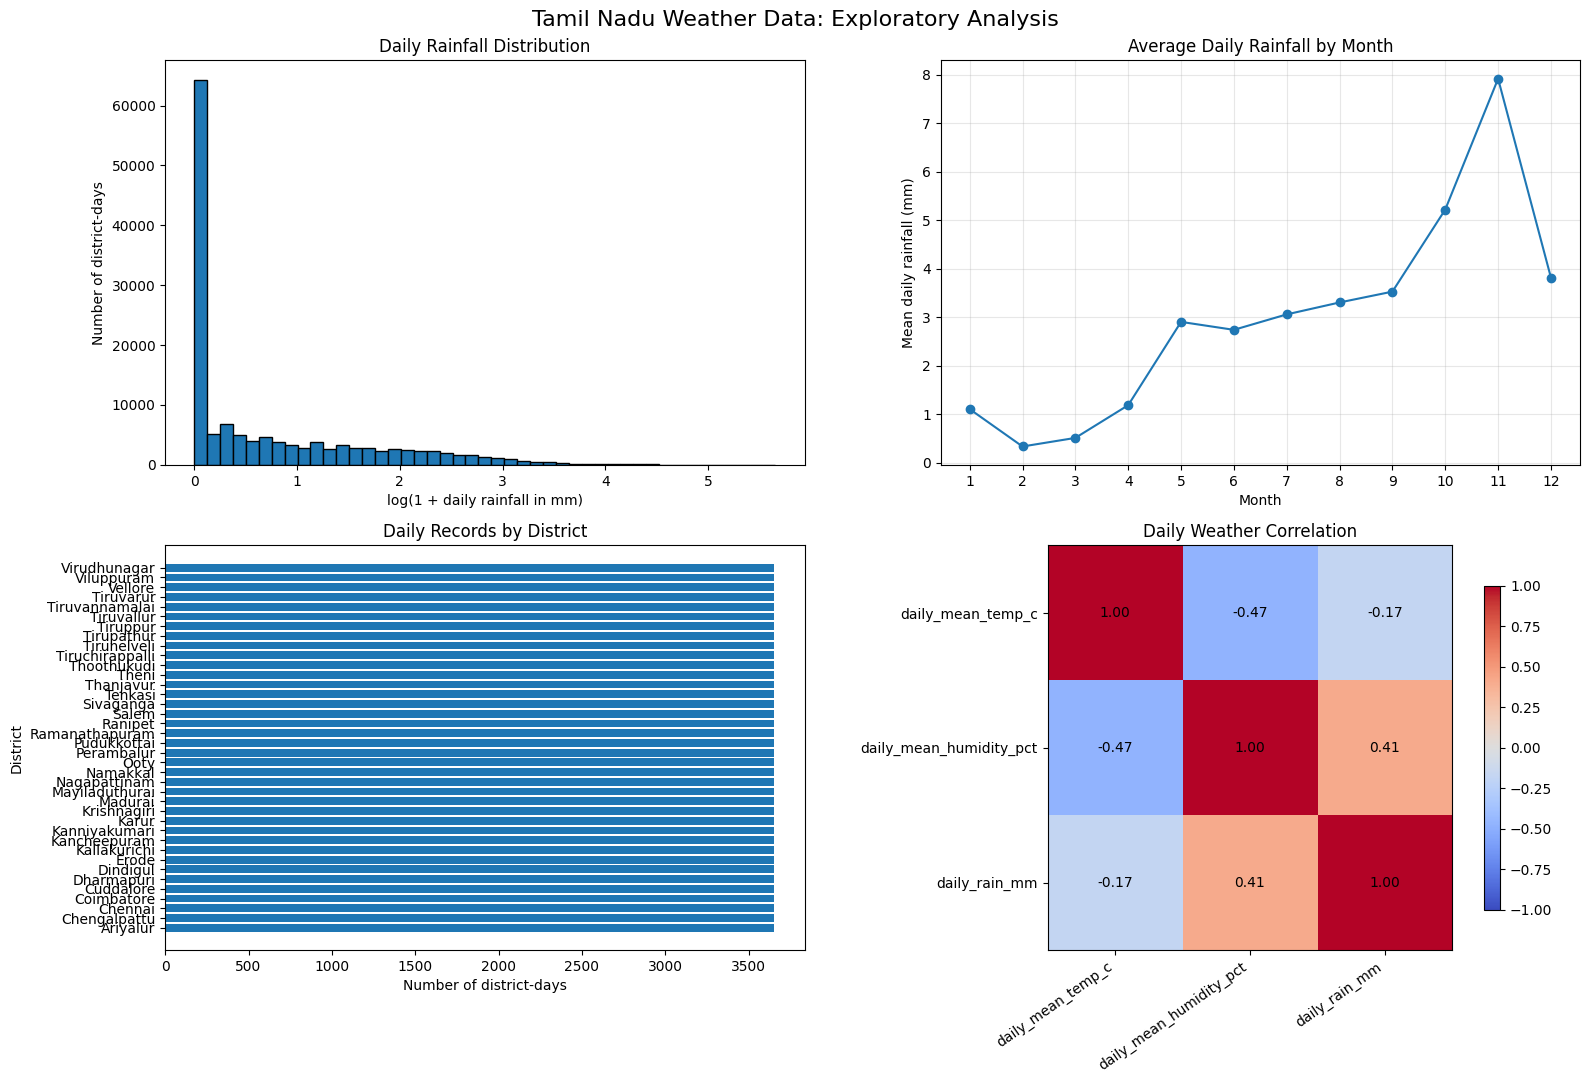

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

viz = daily_weather.copy()
viz["_month"] = pd.to_datetime(viz["_day"]).dt.month

fig, axes = plt.subplots(2, 2, figsize=(16, 11))

# 1. Daily rainfall distribution
rain = pd.to_numeric(viz["daily_rain_mm"], errors="coerce").dropna()
axes[0, 0].hist(np.log1p(rain.clip(lower=0)), bins=45, edgecolor="black")
axes[0, 0].set_title("Daily Rainfall Distribution")
axes[0, 0].set_xlabel("log(1 + daily rainfall in mm)")
axes[0, 0].set_ylabel("Number of district-days")

# 2. Monthly average daily rainfall across district-days
monthly = viz.groupby("_month")["daily_rain_mm"].mean()
axes[0, 1].plot(monthly.index, monthly.values, marker="o")
axes[0, 1].set_title("Average Daily Rainfall by Month")
axes[0, 1].set_xlabel("Month")
axes[0, 1].set_ylabel("Mean daily rainfall (mm)")
axes[0, 1].set_xticks(range(1, 13))
axes[0, 1].grid(True, alpha=0.3)

# 3. Daily records by district
district_counts = viz[district_col].value_counts().sort_values()
axes[1, 0].barh(
    district_counts.index.astype(str),
    district_counts.values
)
axes[1, 0].set_title("Daily Records by District")
axes[1, 0].set_xlabel("Number of district-days")
axes[1, 0].set_ylabel("District")

# 4. Correlation among daily weather variables
numeric_cols = [
    c for c in [
        "daily_mean_temp_c",
        "daily_mean_humidity_pct",
        "daily_rain_mm"
    ]
    if c in viz.columns
]

corr = viz[numeric_cols].corr()
im = axes[1, 1].imshow(corr, vmin=-1, vmax=1, cmap="coolwarm")
axes[1, 1].set_title("Daily Weather Correlation")
axes[1, 1].set_xticks(range(len(numeric_cols)))
axes[1, 1].set_yticks(range(len(numeric_cols)))
axes[1, 1].set_xticklabels(numeric_cols, rotation=35, ha="right")
axes[1, 1].set_yticklabels(numeric_cols)

for r in range(len(numeric_cols)):
    for c in range(len(numeric_cols)):
        axes[1, 1].text(
            c, r, f"{corr.iloc[r, c]:.2f}",
            ha="center", va="center"
        )

fig.colorbar(im, ax=axes[1, 1], shrink=0.8)
plt.suptitle("Tamil Nadu Weather Data: Exploratory Analysis", fontsize=16)
plt.tight_layout()
plt.show()

## Configure a common benchmark sample

Mining every daily transaction with low support can still create many candidates. The default uses up to 12,000 daily district records, sampled reproducibly. Increase `MAX_TRANSACTIONS` after the first run if your Colab runtime has enough memory/time.

In [ ]:
MAX_TRANSACTIONS = 12000
RANDOM_STATE = 42
if len(transactions_all) > MAX_TRANSACTIONS:
    rng = np.random.default_rng(RANDOM_STATE)
    chosen = rng.choice(len(transactions_all), size=MAX_TRANSACTIONS, replace=False)
    transactions = [transactions_all[i] for i in sorted(chosen)]
else:
    transactions = transactions_all.copy()

MIN_SUPPORT = 0.08
MIN_SUPPORT_COUNT = max(1, math.ceil(MIN_SUPPORT * len(transactions)))
print(f"Transactions: {len(transactions):,}")
print(f"Minimum support: {MIN_SUPPORT:.1%} ({MIN_SUPPORT_COUNT:,} transactions)")
print("Sample transactions:", list(transactions[:5]))


Transactions: 12,000
Minimum support: 8.0% (960 transactions)
Sample transactions: [frozenset({'humidity=high', 'rain=light', 'temperature=moderate'}), frozenset({'humidity=high', 'rain=none', 'temperature=moderate'}), frozenset({'humidity=medium', 'rain=none', 'temperature=moderate'}), frozenset({'humidity=medium', 'rain=none', 'temperature=moderate'}), frozenset({'humidity=medium', 'rain=none', 'temperature=moderate'})]


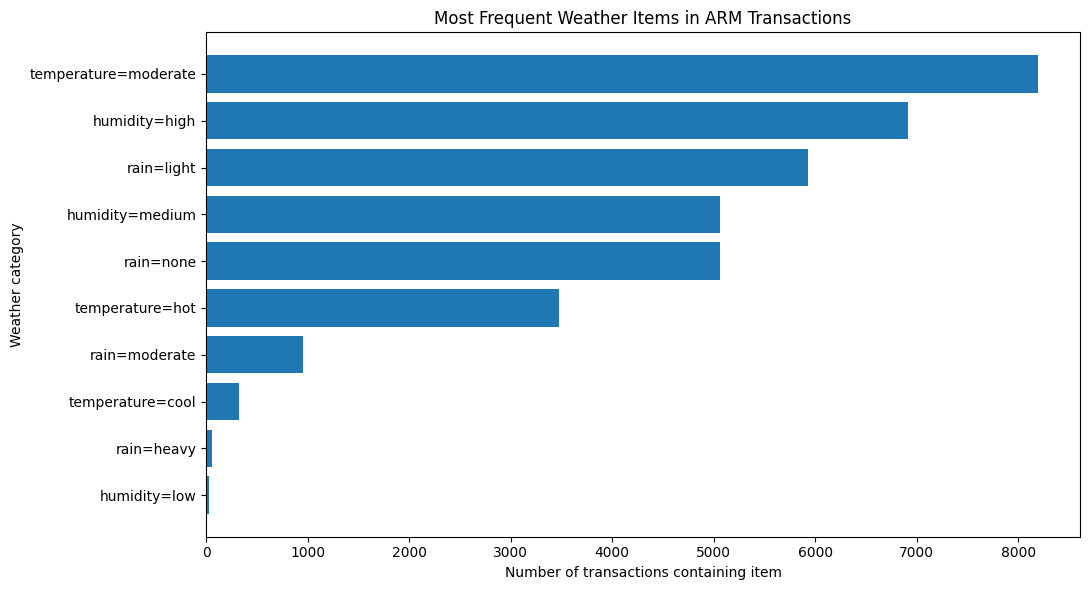

In [ ]:
from collections import Counter
import matplotlib.pyplot as plt

item_counts = Counter(
    item for transaction in transactions for item in transaction
)

top_items = sorted(
    item_counts.items(),
    key=lambda item: item[1]
)[-15:]

labels = [item for item, count in top_items]
counts = [count for item, count in top_items]

plt.figure(figsize=(11, 6))
plt.barh(labels, counts)
plt.xlabel("Number of transactions containing item")
plt.ylabel("Weather category")
plt.title("Most Frequent Weather Items in ARM Transactions")
plt.tight_layout()
plt.show()

## 1. Apriori

Apriori generates candidate itemsets level by level. If an itemset is frequent, all its non-empty subsets must also be frequent.

In [ ]:
def apriori_mine(transactions, min_support=0.08):
    n = len(transactions)
    min_count = max(1, math.ceil(min_support * n))
    item_counts = Counter(item for trans in transactions for item in trans)
    level = {frozenset([i]): c for i, c in item_counts.items() if c >= min_count}
    frequent = dict(level)
    k = 2
    while level:
        prev = list(level)
        prev_set = set(prev)
        candidates = set()
        for a, b in combinations(prev, 2):
            union = a | b
            if len(union) == k and all(frozenset(s) in prev_set for s in combinations(union, k-1)):
                candidates.add(union)
        if not candidates:
            break
        counts = Counter()
        for trans in transactions:
            for cand in candidates:
                if cand.issubset(trans):
                    counts[cand] += 1
        level = {s: c for s, c in counts.items() if c >= min_count}
        frequent.update(level)
        k += 1
    return frequent

t0 = time.perf_counter()
apriori_result = apriori_mine(transactions, MIN_SUPPORT)
apriori_seconds = time.perf_counter() - t0
print(f"Apriori: {len(apriori_result)} frequent itemsets in {apriori_seconds:.2f}s")
display(pd.DataFrame([{"itemset": sorted(s), "length": len(s), "support": c/len(transactions), "count": c}
                      for s, c in apriori_result.items()]).sort_values(["length", "support"], ascending=[True, False]).head(20))


Apriori: 22 frequent itemsets in 0.07s


,itemset,length,support,count
2,[temperature=moderate],1,0.683333,8200
0,[humidity=high],1,0.576083,6913
1,[rain=light],1,0.494083,5929
4,[humidity=medium],1,0.421917,5063
3,[rain=none],1,0.421750,5061
5,[temperature=hot],1,0.289917,3479
6,"[humidity=high, temperature=moderate]",2,0.505417,6065
8,"[rain=light, temperature=moderate]",2,0.333000,3996
7,"[humidity=high, rain=light]",2,0.331333,3976
9,"[rain=none, temperature=moderate]",2,0.275667,3308


## 2. Hash-based Apriori

This variant hashes pairs of items into buckets during the first pass. A bucket whose count is below minimum support cannot contain a frequent pair, reducing pair candidates in the second pass.

In [ ]:
def hash_apriori_mine(transactions, min_support=0.08, bucket_count=997):
    n = len(transactions)
    min_count = max(1, math.ceil(min_support * n))
    item_counts = Counter(i for t in transactions for i in t)
    frequent_items = {i for i, c in item_counts.items() if c >= min_count}
    bucket_counts = Counter()
    for trans in transactions:
        eligible = sorted(i for i in trans if i in frequent_items)
        for a, b in combinations(eligible, 2):
            bucket_counts[hash((a, b)) % bucket_count] += 1
    pair_counts = Counter()
    for trans in transactions:
        eligible = sorted(i for i in trans if i in frequent_items)
        for a, b in combinations(eligible, 2):
            if bucket_counts[hash((a, b)) % bucket_count] >= min_count:
                pair_counts[frozenset((a, b))] += 1
    result = {frozenset([i]): c for i, c in item_counts.items() if c >= min_count}
    result.update({s: c for s, c in pair_counts.items() if c >= min_count})
    # Generate k>=3 candidates using frequent pair support and the Apriori subset property.
    level = {s:c for s,c in result.items() if len(s)==2}
    k = 3
    while level:
        prev = list(level); prev_set = set(prev); candidates=set()
        for a,b in combinations(prev,2):
            u=a|b
            if len(u)==k and all(frozenset(x) in prev_set for x in combinations(u,2)):
                candidates.add(u)
        if not candidates: break
        counts=Counter()
        for trans in transactions:
            for cand in candidates:
                if cand.issubset(trans): counts[cand]+=1
        level={s:c for s,c in counts.items() if c>=min_count}
        result.update(level); k+=1
    return result, bucket_counts

t0=time.perf_counter()
hash_apriori_result, hash_bucket_counts = hash_apriori_mine(transactions, MIN_SUPPORT)
hash_apriori_seconds=time.perf_counter()-t0
print(f"Hash-based Apriori: {len(hash_apriori_result)} frequent itemsets in {hash_apriori_seconds:.2f}s")
print("Hashed buckets:", len(hash_bucket_counts))


Hash-based Apriori: 22 frequent itemsets in 0.10s
Hashed buckets: 11


## 3. Vertical transaction variant (ECLAT)

ECLAT stores each item's transaction-ID set (TID set). Support for an itemset is computed by intersecting TID sets, rather than rescanning every transaction.

In [ ]:
def eclat_mine(transactions, min_support=0.08):
    n=len(transactions); min_count=max(1, math.ceil(min_support*n))
    tidsets=defaultdict(set)
    for tid, trans in enumerate(transactions):
        for item in trans: tidsets[item].add(tid)
    items=sorted((i, tids) for i,tids in tidsets.items() if len(tids)>=min_count)
    result={}
    def extend(prefix, suffix):
        for idx,(item,tids) in enumerate(suffix):
            newset=prefix|frozenset([item]); count=len(tids); result[newset]=count
            next_suffix=[]
            for other, other_tids in suffix[idx+1:]:
                inter=tids & other_tids
                if len(inter)>=min_count: next_suffix.append((other, inter))
            extend(newset,next_suffix)
    extend(frozenset(),items)
    return result

t0=time.perf_counter()
eclat_result=eclat_mine(transactions,MIN_SUPPORT)
eclat_seconds=time.perf_counter()-t0
print(f"ECLAT: {len(eclat_result)} frequent itemsets in {eclat_seconds:.2f}s")


ECLAT: 22 frequent itemsets in 0.01s


## 4. Partition-based Apriori

The partitioning principle mines frequent itemsets locally within each partition, unions those candidates, and counts the candidates globally. Any globally frequent itemset must be frequent in at least one partition.

In [ ]:
def partition_apriori_mine(transactions, min_support=0.08, n_partitions=4):
    n=len(transactions)
    if n==0: return {}
    partitions=[transactions[i:j] for i,j in [(k, min(k+math.ceil(n/min(n_partitions,n)), n)) for k in range(0,n,math.ceil(n/min(n_partitions,n)))]]
    candidates=set()
    for part in partitions:
        local=apriori_mine(part, min_support)
        candidates.update(local.keys())
    global_counts=Counter()
    for trans in transactions:
        for itemset in candidates:
            if itemset.issubset(trans): global_counts[itemset]+=1
    min_count=max(1,math.ceil(min_support*n))
    return {s:c for s,c in global_counts.items() if c>=min_count}

t0=time.perf_counter()
partition_result=partition_apriori_mine(transactions,MIN_SUPPORT,n_partitions=4)
partition_seconds=time.perf_counter()-t0
print(f"Partition-based Apriori: {len(partition_result)} frequent itemsets in {partition_seconds:.2f}s")


Partition-based Apriori: 22 frequent itemsets in 0.09s


## 5. Dynamic Itemset Counting (DIC)

DIC introduces candidate itemsets at checkpoints while scanning the transaction stream, instead of waiting for an entire pass to finish before expanding candidates. This transparent educational implementation updates counts in scan blocks and promotes itemsets when their counts reach the support threshold. It returns itemsets verified against the complete transaction set.

In [ ]:
def dic_mine(transactions, min_support=0.08, block_size=500):
    n=len(transactions)
    if n==0: return {}
    min_count=max(1,math.ceil(min_support*n))
    all_items=sorted(set().union(*transactions))
    candidates={frozenset([i]) for i in all_items}
    counts=Counter()
    # Candidate generation occurs at block boundaries; newly generated candidates
    # are counted from the next block onward, then verified globally for exact support.
    active=set(candidates)
    for start in range(0,n,block_size):
        block=transactions[start:start+block_size]
        for trans in block:
            for cand in list(active):
                if cand.issubset(trans): counts[cand]+=1
        frequent_now={c for c,v in counts.items() if v>=min_count and len(c)==1}
        if frequent_now:
            items=sorted(set().union(*frequent_now))
            for size in range(2,len(items)+1):
                for combo in combinations(items,size):
                    cand=frozenset(combo)
                    if cand not in active and all(frozenset(x) in active or len(x)==1 for x in combinations(cand,len(cand)-1)):
                        active.add(cand)
    # Exact final verification avoids returning false positives from partial counts.
    verified=Counter()
    for trans in transactions:
        for cand in active:
            if cand.issubset(trans): verified[cand]+=1
    return {s:c for s,c in verified.items() if c>=min_count}

t0=time.perf_counter()
dic_result=dic_mine(transactions,MIN_SUPPORT)
dic_seconds=time.perf_counter()-t0
print(f"DIC educational implementation: {len(dic_result)} frequent itemsets in {dic_seconds:.2f}s")


DIC educational implementation: 22 frequent itemsets in 0.14s


## 6. FP-Growth

FP-Growth compresses transactions into an FP-tree and mines patterns without Apriori's explicit candidate generation. This cell uses `mlxtend`'s maintained implementation. If installation is unavailable, the notebook still has the other algorithm implementations.

In [ ]:
try:
    from mlxtend.preprocessing import TransactionEncoder
    from mlxtend.frequent_patterns import fpgrowth
    encoder = TransactionEncoder()
    encoded = encoder.fit(transactions).transform(transactions)
    transaction_df = pd.DataFrame(encoded, columns=encoder.columns_)
    t0=time.perf_counter()
    fp_df=fpgrowth(transaction_df, min_support=MIN_SUPPORT, use_colnames=True)
    fp_seconds=time.perf_counter()-t0
    fp_result={frozenset(row["itemsets"]): int(round(row["support"]*len(transactions))) for _,row in fp_df.iterrows()}
    print(f"FP-Growth: {len(fp_result)} frequent itemsets in {fp_seconds:.2f}s")
    display(fp_df.sort_values("support",ascending=False).head(20))
except ImportError:
    print("mlxtend is not installed. Run: %pip -q install mlxtend, then rerun this cell.")
    fp_result={}
    fp_seconds=np.nan


FP-Growth: 22 frequent itemsets in 0.78s


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,support,itemsets
0,0.683333,(temperature=moderate)
1,0.576083,(humidity=high)
6,0.505417,"(humidity=high, temperature=moderate)"
2,0.494083,(rain=light)
4,0.421917,(humidity=medium)
3,0.421750,(rain=none)
7,0.333000,"(rain=light, temperature=moderate)"
8,0.331333,"(humidity=high, rain=light)"
5,0.289917,(temperature=hot)
9,0.286750,"(humidity=high, rain=light, temperature=moderate)"


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

## 7. A-Close (closed frequent itemsets)

A frequent itemset is closed when none of its proper supersets has the same support. A-Close algorithms exploit closed frequent itemsets to compactly represent support information. This cell derives the closed itemsets from the frequent itemsets mined by Apriori.

In [ ]:
def closed_itemsets(frequent_itemsets):
    closed={}
    items=list(frequent_itemsets.items())
    for itemset,support in items:
        is_closed=True
        for superset,sup_support in items:
            if len(superset)>len(itemset) and itemset.issubset(superset) and support==sup_support:
                is_closed=False
                break
        if is_closed: closed[itemset]=support
    return closed

aclose_result=closed_itemsets(apriori_result)
print(f"Closed frequent itemsets (A-Close output representation): {len(aclose_result)}")
display(pd.DataFrame([{"itemset":sorted(s),"length":len(s),"count":c,"support":c/len(transactions)}
                      for s,c in aclose_result.items()]).sort_values(["length","support"],ascending=[False,False]).head(20))


Closed frequent itemsets (A-Close output representation): 22


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

,itemset,length,count,support
17,"[humidity=high, rain=light, temperature=moderate]",3,3441,0.286750
18,"[humidity=high, rain=none, temperature=moderate]",3,1741,0.145083
19,"[humidity=medium, rain=none, temperature=moder...",3,1557,0.129750
21,"[humidity=medium, rain=none, temperature=hot]",3,1449,0.120750
20,"[humidity=medium, rain=light, temperature=hot]",3,1375,0.114583
6,"[humidity=high, temperature=moderate]",2,6065,0.505417
8,"[rain=light, temperature=moderate]",2,3996,0.333000
7,"[humidity=high, rain=light]",2,3976,0.331333
9,"[rain=none, temperature=moderate]",2,3308,0.275667
11,"[humidity=medium, rain=none]",2,3065,0.255417


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

## 8. Pincer Search — maximal frequent itemsets

Pincer Search searches for maximal frequent itemsets using both bottom-up frequent-itemset discovery and a maximal-candidate border. The following compact educational variant uses Apriori levels and removes any frequent itemset that has a frequent proper superset; the resulting maximal itemsets are exact for the mined frequent-itemset collection, though this is not a full optimized Pincer Search implementation.

In [ ]:
def maximal_frequent_itemsets(frequent_itemsets):
    sets=list(frequent_itemsets)
    return {s:frequent_itemsets[s] for s in sets
            if not any(len(t)>len(s) and s.issubset(t) for t in sets)}

pincer_result=maximal_frequent_itemsets(apriori_result)
print(f"Maximal frequent itemsets (Pincer-style output): {len(pincer_result)}")
display(pd.DataFrame([{"itemset":sorted(s),"length":len(s),"count":c,"support":c/len(transactions)}
                      for s,c in pincer_result.items()]).sort_values(["length","support"],ascending=[False,False]).head(20))


Maximal frequent itemsets (Pincer-style output): 5


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

,itemset,length,count,support
0,"[humidity=high, rain=light, temperature=moderate]",3,3441,0.286750
1,"[humidity=high, rain=none, temperature=moderate]",3,1741,0.145083
2,"[humidity=medium, rain=none, temperature=moder...",3,1557,0.129750
4,"[humidity=medium, rain=none, temperature=hot]",3,1449,0.120750
3,"[humidity=medium, rain=light, temperature=hot]",3,1375,0.114583


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

Add MAFIA-inspired mining

## 9. Compare algorithm outputs and runtime

Counts should match for exact algorithms on the same transaction sample and support threshold. Hash-based Apriori and partition-based Apriori should also return the same globally frequent itemsets when implemented correctly. Differences are useful debugging signals.

In [ ]:
import numpy as np
import math
import time
from collections import Counter
import pandas as pd

def mafia_bitmap_mine(transactions, min_support=0.08):
    n = len(transactions)

    if n == 0:
        return {}

    min_count = max(1, math.ceil(min_support * n))

    item_counts = Counter(
        item for transaction in transactions for item in transaction
    )

    items = [
        item for item, count in item_counts.items()
        if count >= min_count
    ]
    items.sort(key=lambda item: (-item_counts[item], str(item)))

    # One packed vertical bitmap per item
    bitmaps = {}

    for item in items:
        present = np.fromiter(
            (item in transaction for transaction in transactions),
            dtype=np.uint8,
            count=n
        )
        bitmaps[item] = np.packbits(present, bitorder="little")

    # Fast byte-level population count
    popcount = np.array(
        [i.bit_count() for i in range(256)],
        dtype=np.uint8
    )

    def support_count(bitmap):
        return int(popcount[bitmap].sum(dtype=np.int64))

    maximal_candidates = []

    def search(prefix, prefix_bitmap, tail):
        has_frequent_extension = False

        for index, item in enumerate(tail):
            if prefix_bitmap is None:
                candidate_bitmap = bitmaps[item]
            else:
                candidate_bitmap = np.bitwise_and(
                    prefix_bitmap, bitmaps[item]
                )

            count = support_count(candidate_bitmap)

            if count >= min_count:
                has_frequent_extension = True
                search(
                    prefix + (item,),
                    candidate_bitmap,
                    tail[index + 1:]
                )

        if prefix and not has_frequent_extension:
            maximal_candidates.append(
                (frozenset(prefix), support_count(prefix_bitmap))
            )

    search(tuple(), None, items)

    # Remove duplicate candidates
    unique_candidates = dict(maximal_candidates)

    # Remove any candidate that is a proper subset of another candidate
    mafia_result = {
        itemset: count
        for itemset, count in unique_candidates.items()
        if not any(
            itemset < other
            for other in unique_candidates
        )
    }

    return mafia_result


t0 = time.perf_counter()

mafia_result = mafia_bitmap_mine(
    transactions,
    MIN_SUPPORT
)

mafia_seconds = time.perf_counter() - t0

print("MAFIA-inspired bitmap DFS")
print("Maximal itemsets:", len(mafia_result))
print("Runtime (seconds):", round(mafia_seconds, 3))

mafia_table = pd.DataFrame([
    {
        "itemset": sorted(itemset),
        "length": len(itemset),
        "support_count": count,
        "support": count / len(transactions)
    }
    for itemset, count in mafia_result.items()
])

if not mafia_table.empty:
    display(
        mafia_table.sort_values(
            ["length", "support"],
            ascending=[False, False]
        ).head(25)
    )

print(
    "MAFIA-inspired vs Pincer-style maximal sets match:",
    set(mafia_result) == set(pincer_result)
)

MAFIA-inspired bitmap DFS
Maximal itemsets: 5
Runtime (seconds): 0.021


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

,itemset,length,support_count,support
0,"[humidity=high, rain=light, temperature=moderate]",3,3441,0.286750
1,"[humidity=high, rain=none, temperature=moderate]",3,1741,0.145083
2,"[humidity=medium, rain=none, temperature=moder...",3,1557,0.129750
4,"[humidity=medium, rain=none, temperature=hot]",3,1449,0.120750
3,"[humidity=medium, rain=light, temperature=hot]",3,1375,0.114583


MAFIA-inspired vs Pincer-style maximal sets match: True


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

,algorithm,pattern_count,runtime_seconds,output_type
2,ECLAT,22,0.014360,All frequent
5,MAFIA-inspired bitmap DFS,5,0.021311,Maximal frequent
0,Apriori,22,0.073004,All frequent
3,Partition-based Apriori,22,0.094040,All frequent
1,Hash-based Apriori,22,0.104960,All frequent
4,DIC educational,22,0.143736,All frequent
6,FP-Growth,22,0.782818,All frequent


Apriori vs ECLAT: True
Apriori vs partition-based Apriori: True
Apriori vs hash-based Apriori: True
Apriori vs FP-Growth: True
MAFIA-inspired vs Pincer maximal itemsets: True


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

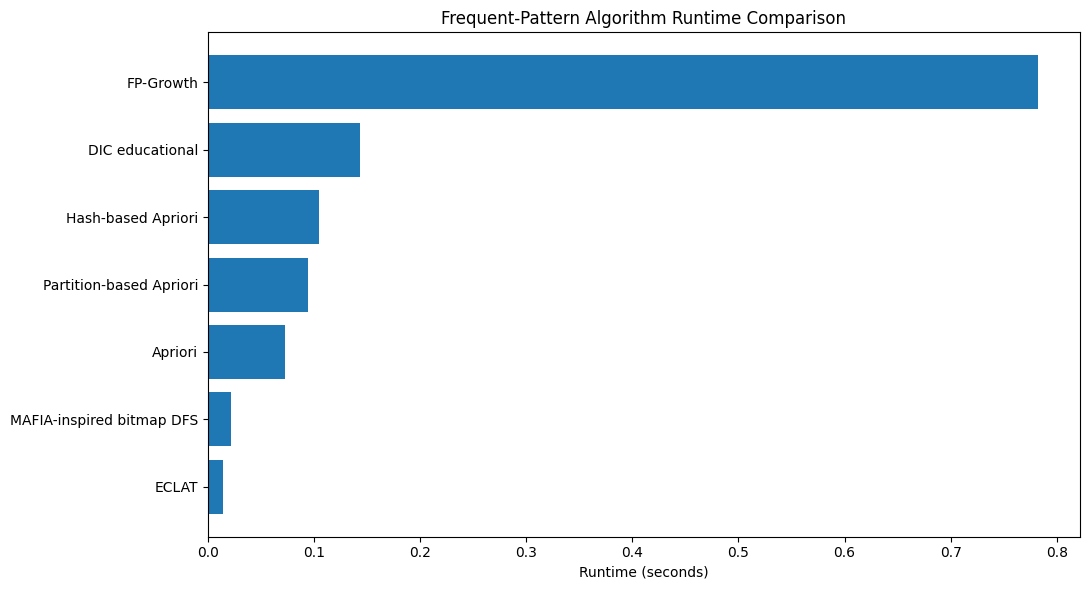

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

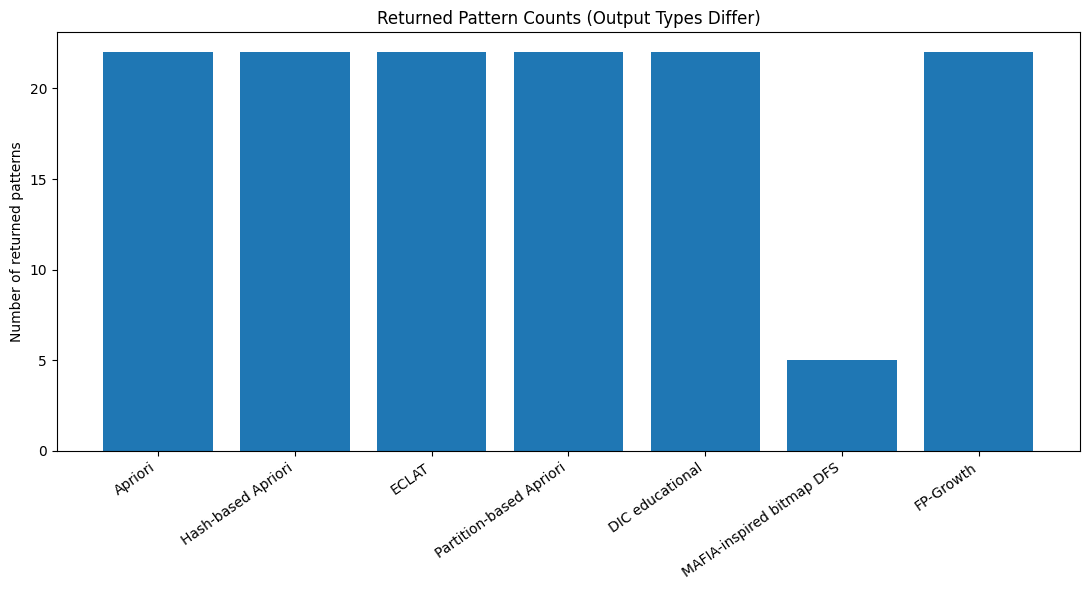

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

In [ ]:
benchmark_rows = [
    {
        "algorithm": "Apriori",
        "pattern_count": len(apriori_result),
        "runtime_seconds": apriori_seconds,
        "output_type": "All frequent"
    },
    {
        "algorithm": "Hash-based Apriori",
        "pattern_count": len(hash_apriori_result),
        "runtime_seconds": hash_apriori_seconds,
        "output_type": "All frequent"
    },
    {
        "algorithm": "ECLAT",
        "pattern_count": len(eclat_result),
        "runtime_seconds": eclat_seconds,
        "output_type": "All frequent"
    },
    {
        "algorithm": "Partition-based Apriori",
        "pattern_count": len(partition_result),
        "runtime_seconds": partition_seconds,
        "output_type": "All frequent"
    },
    {
        "algorithm": "DIC educational",
        "pattern_count": len(dic_result),
        "runtime_seconds": dic_seconds,
        "output_type": "All frequent"
    }
]

if "mafia_result" in globals() and "mafia_seconds" in globals():
    benchmark_rows.append({
        "algorithm": "MAFIA-inspired bitmap DFS",
        "pattern_count": len(mafia_result),
        "runtime_seconds": mafia_seconds,
        "output_type": "Maximal frequent"
    })
else:
    print("MAFIA results unavailable. Run the MAFIA cell before benchmarking.")

if "fp_result" in globals() and not np.isnan(fp_seconds):
    benchmark_rows.append({
        "algorithm": "FP-Growth",
        "pattern_count": len(fp_result),
        "runtime_seconds": fp_seconds,
        "output_type": "All frequent"
    })

benchmark_df = pd.DataFrame(benchmark_rows)

display(benchmark_df.sort_values("runtime_seconds"))

print(
    "Apriori vs ECLAT:",
    set(apriori_result) == set(eclat_result)
)
print(
    "Apriori vs partition-based Apriori:",
    set(apriori_result) == set(partition_result)
)
print(
    "Apriori vs hash-based Apriori:",
    set(apriori_result) == set(hash_apriori_result)
)

if "fp_result" in globals() and not np.isnan(fp_seconds):
    print(
        "Apriori vs FP-Growth:",
        set(apriori_result) == set(fp_result)
    )

if "mafia_result" in globals() and "pincer_result" in globals():
    print(
        "MAFIA-inspired vs Pincer maximal itemsets:",
        set(mafia_result) == set(pincer_result)
    )

# Runtime plot
runtime_df = benchmark_df.dropna(
    subset=["runtime_seconds"]
).sort_values("runtime_seconds")

plt.figure(figsize=(11, 6))
plt.barh(
    runtime_df["algorithm"],
    runtime_df["runtime_seconds"]
)
plt.xlabel("Runtime (seconds)")
plt.title("Frequent-Pattern Algorithm Runtime Comparison")
plt.tight_layout()
plt.show()

# Pattern counts are different kinds of output for maximal mining
plt.figure(figsize=(11, 6))
plt.bar(
    benchmark_df["algorithm"],
    benchmark_df["pattern_count"]
)
plt.ylabel("Number of returned patterns")
plt.title("Returned Pattern Counts (Output Types Differ)")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

# Phase 6 — Association Rules

Generate rules from frequent itemsets with confidence and lift. A rule such as `temperature=hot → rain=none` is an association, not a causal claim.

In [ ]:
from itertools import combinations
import pandas as pd

def generate_rules(frequent_itemsets, n_transactions, min_confidence=0.5):
    columns = [
        "antecedent",
        "consequent",
        "support",
        "confidence",
        "lift"
    ]

    if n_transactions <= 0 or not frequent_itemsets:
        return pd.DataFrame(columns=columns)

    support_map = {
        frozenset(itemset): count / n_transactions
        for itemset, count in frequent_itemsets.items()
    }

    rules = []
    seen_rules = set()

    for itemset, count in frequent_itemsets.items():
        itemset = frozenset(itemset)

        if len(itemset) < 2:
            continue

        support = count / n_transactions

        for r in range(1, len(itemset)):
            for antecedent_tuple in combinations(
                sorted(itemset, key=str), r
            ):
                antecedent = frozenset(antecedent_tuple)
                consequent = itemset - antecedent

                antecedent_support = support_map.get(
                    antecedent, 0
                )
                consequent_support = support_map.get(
                    consequent, 0
                )

                if antecedent_support <= 0 or consequent_support <= 0:
                    continue

                confidence = support / antecedent_support

                if confidence < min_confidence:
                    continue

                lift = confidence / consequent_support

                rule_key = (
                    tuple(sorted(antecedent, key=str)),
                    tuple(sorted(consequent, key=str))
                )

                if rule_key in seen_rules:
                    continue

                seen_rules.add(rule_key)

                rules.append({
                    "antecedent": list(rule_key[0]),
                    "consequent": list(rule_key[1]),
                    "support": support,
                    "confidence": confidence,
                    "lift": lift
                })

    rules_df = pd.DataFrame(rules, columns=columns)

    if not rules_df.empty:
        rules_df = rules_df.sort_values(
            ["lift", "confidence"],
            ascending=False
        ).reset_index(drop=True)

    return rules_df


rules_df = generate_rules(
    apriori_result,
    len(transactions),
    min_confidence=0.5
)

if not rules_df.empty:
    display(rules_df.head(25))
else:
    print(
        "No association rules satisfy the minimum "
        "confidence threshold."
    )

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

,antecedent,consequent,support,confidence,lift
0,"[humidity=medium, rain=light]",[temperature=hot],0.114583,0.704045,2.428439
1,"[rain=none, temperature=hot]",[humidity=medium],0.120750,0.869226,2.060184
2,[temperature=hot],[humidity=medium],0.238000,0.820926,1.945705
3,[humidity=medium],[temperature=hot],0.238000,0.564092,1.945705
4,"[rain=light, temperature=hot]",[humidity=medium],0.114583,0.782584,1.854831
5,"[humidity=medium, temperature=moderate]",[rain=none],0.129750,0.732706,1.737299
6,"[rain=light, temperature=moderate]",[humidity=high],0.286750,0.861111,1.494768
7,[rain=none],[humidity=medium],0.255417,0.605612,1.435382
8,[humidity=medium],[rain=none],0.255417,0.605372,1.435382
9,"[humidity=high, rain=none]",[temperature=moderate],0.145083,0.882860,1.291990


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

Association-rule visualizations

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

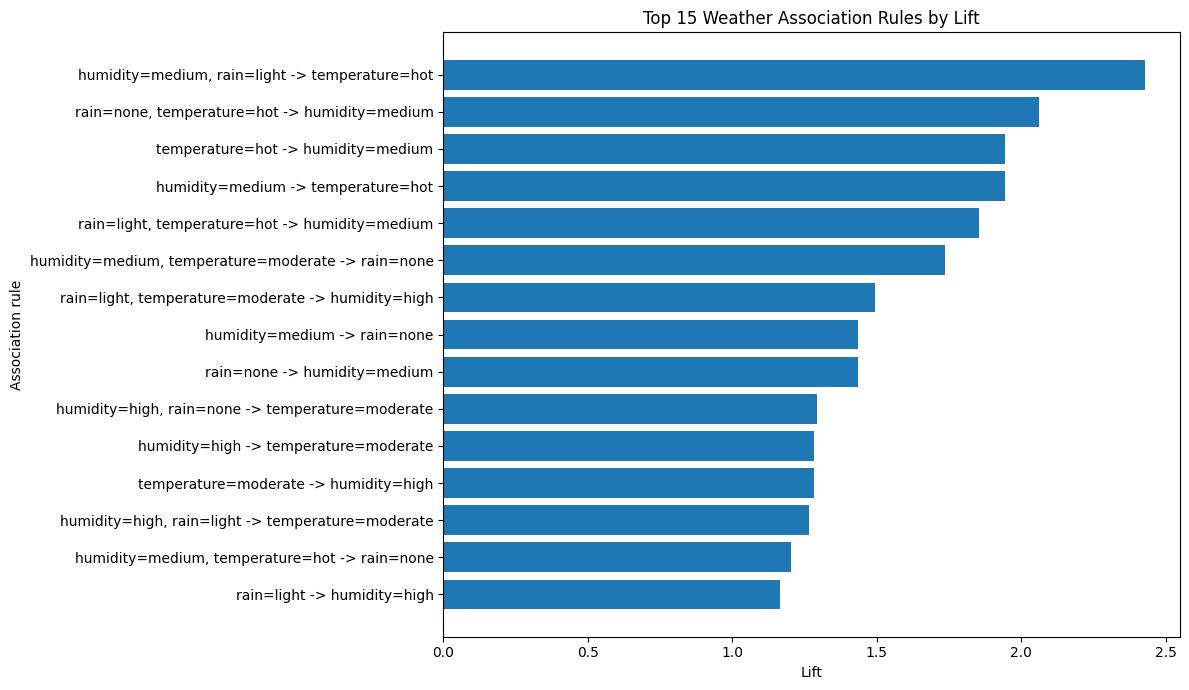

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

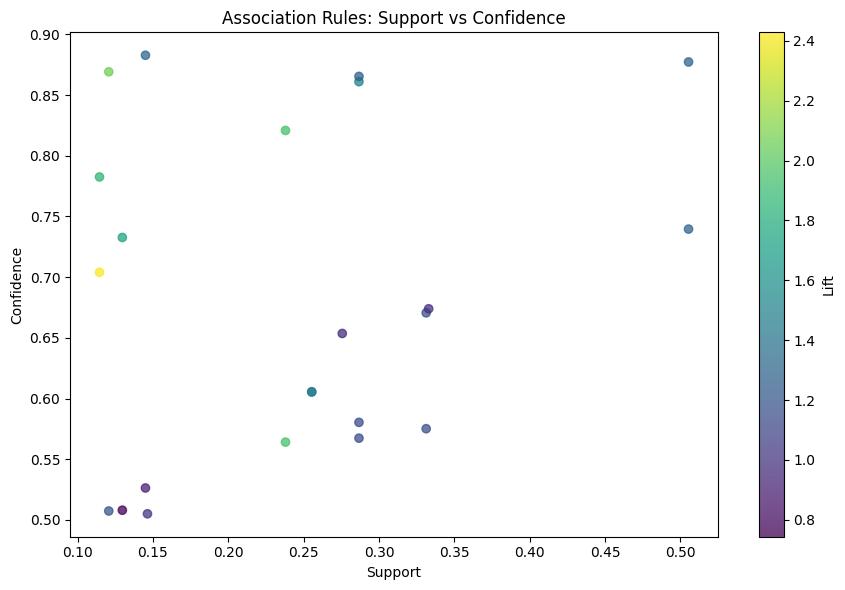

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

In [ ]:
import matplotlib.pyplot as plt

if rules_df.empty:
    print("No rules available for plotting.")
else:
    plot_rules = rules_df.copy()

    plot_rules["rule"] = plot_rules.apply(
        lambda row:
            f"{', '.join(row['antecedent'])} -> "
            f"{', '.join(row['consequent'])}",
        axis=1
    )

    # Top rules by lift
    top_rules = plot_rules.nlargest(15, "lift").sort_values("lift")

    plt.figure(figsize=(12, 7))
    plt.barh(top_rules["rule"], top_rules["lift"])
    plt.xlabel("Lift")
    plt.ylabel("Association rule")
    plt.title("Top 15 Weather Association Rules by Lift")
    plt.tight_layout()
    plt.show()

    # Support-confidence relationship
    plt.figure(figsize=(9, 6))
    points = plt.scatter(
        plot_rules["support"],
        plot_rules["confidence"],
        c=plot_rules["lift"],
        alpha=0.75
    )
    plt.colorbar(points, label="Lift")
    plt.xlabel("Support")
    plt.ylabel("Confidence")
    plt.title("Association Rules: Support vs Confidence")
    plt.tight_layout()
    plt.show()

# Phase 7 — Decision Tree Classification

The target is **daily rain category** derived from daily precipitation totals. Features are daily mean temperature, optional daily mean humidity, district, month, and day-of-year. A chronological split avoids randomly mixing later dates into training data. We compare information criteria (`entropy` and `log_loss`) and `gini`, tune hyperparameters with a small validation grid, report metrics, and show a trace of decision paths for sample rows.

In [ ]:
from sklearn.model_selection import ParameterGrid
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier, export_text, plot_tree
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, classification_report, confusion_matrix
import matplotlib.pyplot as plt

tree_df=daily_weather.copy()
tree_df["month"]=tree_df["_day"].dt.month
tree_df["day_of_year"]=tree_df["_day"].dt.dayofyear
tree_df["rain_category"] = pd.cut(
    tree_df["daily_rain_mm"],
    bins=[-0.001, 0.1, 10, 50, np.inf],
    labels=["none", "light", "moderate", "heavy"],
    include_lowest=True
)
feature_cols = ["daily_mean_temp_c", "month", "day_of_year", district_col]
if "daily_mean_humidity_pct" in tree_df.columns:
    feature_cols.insert(1, "daily_mean_humidity_pct")

# Drop genuinely missing targets before converting labels to strings. This avoids
# accidentally treating the text "nan" as a fifth rainfall class.
tree_df = tree_df.dropna(subset=feature_cols + ["rain_category"]).copy()
tree_df["rain_category"] = tree_df["rain_category"].astype(str)
tree_df = tree_df.sort_values("_day").reset_index(drop=True)
X=tree_df[feature_cols].copy()
y=tree_df["rain_category"].copy()
# Chronological split by date, not random row order
unique_days=np.sort(tree_df["_day"].unique())
cutoff_day=unique_days[int(len(unique_days)*0.8)]
train_mask=tree_df["_day"]<cutoff_day
X_train,X_test=X.loc[train_mask],X.loc[~train_mask]
y_train,y_test=y.loc[train_mask],y.loc[~train_mask]
cat_cols=[district_col]
num_cols=[c for c in feature_cols if c not in cat_cols]
preprocessor=ColumnTransformer([
    ("district",OneHotEncoder(handle_unknown="ignore"),cat_cols),
    ("numeric","passthrough",num_cols)
])
print("Feature columns:",feature_cols)
print("Training rows:",len(X_train),"Test rows:",len(X_test),"Chronological cutoff:",cutoff_day)
print("Training class distribution:")
display(y_train.value_counts(normalize=True).rename("proportion").to_frame())


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

Feature columns: ['daily_mean_temp_c', 'daily_mean_humidity_pct', 'month', 'day_of_year', 'district']
Training rows: 111036 Test rows: 27778 Chronological cutoff: 2023-01-01T00:00:00.000000000
Training class distribution:


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

,proportion
rain_category,
none,0.474315
light,0.445909
moderate,0.075687
heavy,0.004089


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

In [ ]:
# Compare split criteria and hyperparameters on a validation split from the training period
train_days = np.sort(tree_df.loc[train_mask, "_day"].unique())
if len(train_days) < 2:
    raise ValueError("Not enough unique training dates to create an inner validation split.")

val_index = min(int(len(train_days) * 0.8), len(train_days) - 1)
val_cutoff = train_days[val_index]
inner_train = train_mask & (tree_df["_day"] < val_cutoff)
validation_mask = train_mask & (tree_df["_day"] >= val_cutoff)

X_inner_train = tree_df.loc[inner_train, feature_cols]
y_inner_train = tree_df.loc[inner_train, "rain_category"]
X_val = tree_df.loc[validation_mask, feature_cols]
y_val = tree_df.loc[validation_mask, "rain_category"]

if X_inner_train.empty or X_val.empty:
    raise ValueError(
        "The inner training or validation split is empty. Check the date range and split ratio."
    )

print("Inner training rows:", len(X_inner_train))
print("Validation rows:", len(X_val))
print("Validation starts:", val_cutoff)

param_grid = {
    "criterion": ["gini", "entropy", "log_loss"],
    "max_depth": [4, 8, 12, None],
    "min_samples_leaf": [1, 5, 20],
    "class_weight": [None, "balanced"]
}

grid_rows = []
best_model = None
best_score = -1
best_params = None

for params in ParameterGrid(param_grid):
    pipe = Pipeline([
        ("prep", preprocessor),
        ("tree", DecisionTreeClassifier(random_state=RANDOM_STATE, **params))
    ])
    pipe.fit(X_inner_train, y_inner_train)
    pred = pipe.predict(X_val)
    score = accuracy_score(y_val, pred)
    grid_rows.append({**params, "validation_accuracy": score})

    if score > best_score:
        best_score = score
        best_model = pipe
        best_params = params

grid_results = pd.DataFrame(grid_rows).sort_values(
    "validation_accuracy", ascending=False
).reset_index(drop=True)
print("Configurations tested:", len(grid_results))
print("Best validation parameters:", best_params)
print("Best validation accuracy:", round(best_score, 4))
display(grid_results.head(15))


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

Inner training rows: 88806
Validation rows: 22230
Validation starts: 2021-05-26T00:00:00.000000000


Streaming output truncated to the last 5000 lines.
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replac

Configurations tested: 72
Best validation parameters: {'class_weight': None, 'criterion': 'gini', 'max_depth': 12, 'min_samples_leaf': 20}
Best validation accuracy: 0.6904


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,class_weight,criterion,max_depth,min_samples_leaf,validation_accuracy
0,None,gini,12.0,20,0.690373
1,None,gini,12.0,1,0.690283
2,None,gini,12.0,5,0.689654
3,None,entropy,8.0,1,0.686550
4,None,log_loss,8.0,1,0.686550
5,None,entropy,8.0,5,0.686280
6,None,log_loss,8.0,5,0.686280
7,None,log_loss,12.0,20,0.686145
8,None,entropy,12.0,20,0.686145
9,None,entropy,12.0,5,0.685875


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

In [ ]:
# Fit the selected configuration on all training data and evaluate once on held-out future dates
best_tree=Pipeline([
    ("prep",preprocessor),
    ("tree",DecisionTreeClassifier(random_state=RANDOM_STATE,**best_params))
])
best_tree.fit(X_train,y_train)
y_pred=best_tree.predict(X_test)
print("Test accuracy:",round(accuracy_score(y_test,y_pred),4))
print("\nClassification report:")
print(classification_report(y_test,y_pred,zero_division=0))
print("Confusion matrix (labels:",list(best_tree.named_steps["tree"].classes_),")")
display(pd.DataFrame(confusion_matrix(y_test,y_pred,labels=best_tree.named_steps["tree"].classes_),
                     index=best_tree.named_steps["tree"].classes_,
                     columns=best_tree.named_steps["tree"].classes_))


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

Test accuracy: 0.6891

Classification report:


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

              precision    recall  f1-score   support

       heavy       0.08      0.01      0.02       158
       light       0.67      0.74      0.70     13382
    moderate       0.56      0.33      0.42      2572
        none       0.74      0.72      0.73     11666

    accuracy                           0.69     27778
   macro avg       0.51      0.45      0.47     27778
weighted avg       0.68      0.69      0.68     27778

Confusion matrix (labels: ['heavy', 'light', 'moderate', 'none'] )


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,heavy,light,moderate,none
heavy,2,41,115,0
light,7,9891,547,2937
moderate,17,1650,861,44
none,0,3272,6,8388


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

Decision-tree hyperparameter visualization

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

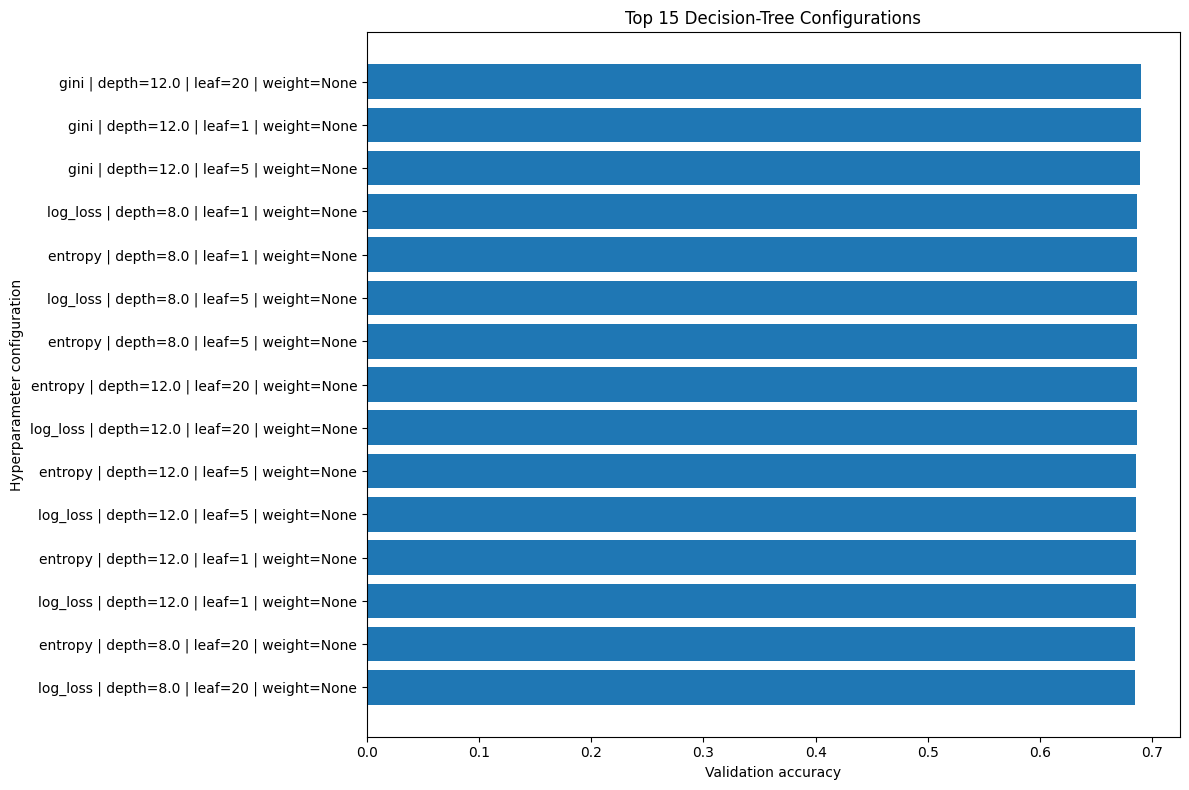

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

In [ ]:
import matplotlib.pyplot as plt

top_configs = grid_results.head(15).copy()

top_configs["configuration"] = top_configs.apply(
    lambda row:
        f"{row['criterion']} | depth={row['max_depth']} | "
        f"leaf={row['min_samples_leaf']} | "
        f"weight={row['class_weight']}",
    axis=1
)

top_configs = top_configs.sort_values("validation_accuracy")

plt.figure(figsize=(12, 8))
plt.barh(
    top_configs["configuration"],
    top_configs["validation_accuracy"]
)
plt.xlabel("Validation accuracy")
plt.ylabel("Hyperparameter configuration")
plt.title("Top 15 Decision-Tree Configurations")
plt.tight_layout()
plt.show()

Decision-tree evaluation plots

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

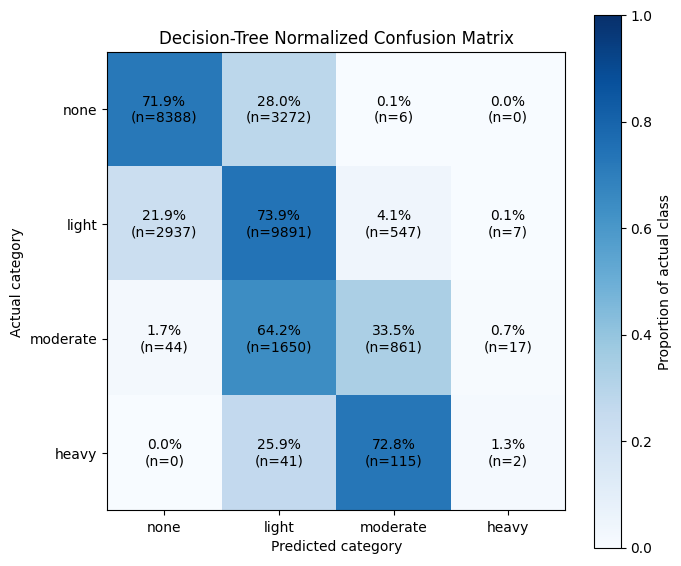

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

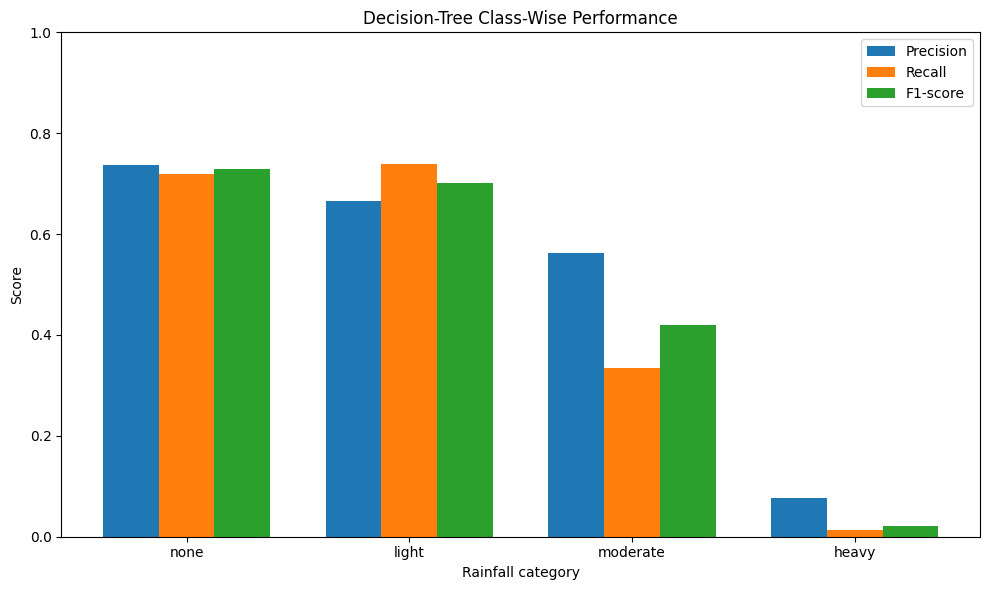

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

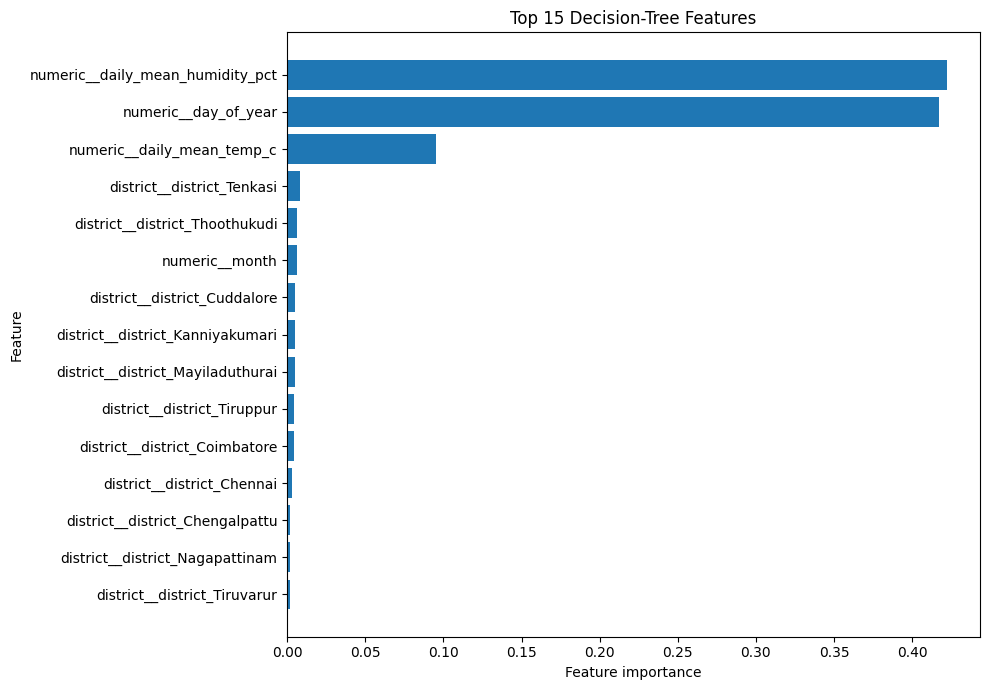

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import (
    confusion_matrix,
    precision_recall_fscore_support
)

labels = ["none", "light", "moderate", "heavy"]

# 1. Normalized confusion matrix
cm = confusion_matrix(y_test, y_pred, labels=labels)
row_totals = cm.sum(axis=1, keepdims=True)

cm_normalized = np.divide(
    cm,
    row_totals,
    out=np.zeros_like(cm, dtype=float),
    where=row_totals != 0
)

fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(cm_normalized, vmin=0, vmax=1, cmap="Blues")

ax.set_xticks(range(len(labels)))
ax.set_yticks(range(len(labels)))
ax.set_xticklabels(labels)
ax.set_yticklabels(labels)
ax.set_xlabel("Predicted category")
ax.set_ylabel("Actual category")
ax.set_title("Decision-Tree Normalized Confusion Matrix")

for i in range(len(labels)):
    for j in range(len(labels)):
        ax.text(
            j, i,
            f"{cm_normalized[i, j]:.1%}\n(n={cm[i, j]})",
            ha="center", va="center"
        )

fig.colorbar(im, ax=ax, label="Proportion of actual class")
plt.tight_layout()
plt.show()

# 2. Per-class precision, recall, and F1-score
precision, recall, f1, _ = precision_recall_fscore_support(
    y_test,
    y_pred,
    labels=labels,
    zero_division=0
)

x = np.arange(len(labels))
width = 0.25

plt.figure(figsize=(10, 6))
plt.bar(x - width, precision, width, label="Precision")
plt.bar(x, recall, width, label="Recall")
plt.bar(x + width, f1, width, label="F1-score")

plt.xticks(x, labels)
plt.ylim(0, 1)
plt.ylabel("Score")
plt.xlabel("Rainfall category")
plt.title("Decision-Tree Class-Wise Performance")
plt.legend()
plt.tight_layout()
plt.show()

# 3. Top feature importances
tree_model = best_tree.named_steps["tree"]
feature_names = best_tree.named_steps["prep"].get_feature_names_out()

importance = pd.DataFrame({
    "feature": feature_names,
    "importance": tree_model.feature_importances_
}).sort_values("importance", ascending=False).head(15)

importance = importance.sort_values("importance")

plt.figure(figsize=(10, 7))
plt.barh(importance["feature"], importance["importance"])
plt.xlabel("Feature importance")
plt.ylabel("Feature")
plt.title("Top 15 Decision-Tree Features")
plt.tight_layout()
plt.show()

In [ ]:
# Compare all information criteria using the same selected depth/leaf settings
criterion_rows=[]
for criterion in ["gini","entropy","log_loss"]:
    model=Pipeline([
        ("prep",preprocessor),
        ("tree",DecisionTreeClassifier(
            random_state=RANDOM_STATE,criterion=criterion,
            max_depth=best_params["max_depth"],
            min_samples_leaf=best_params["min_samples_leaf"],
            class_weight=best_params["class_weight"]
        ))
    ])
    model.fit(X_train,y_train)
    pred=model.predict(X_test)
    criterion_rows.append({"criterion":criterion,"test_accuracy":accuracy_score(y_test,pred),
                           "tree_depth":model.named_steps["tree"].get_depth(),
                           "leaves":model.named_steps["tree"].get_n_leaves()})
criterion_comparison=pd.DataFrame(criterion_rows).sort_values("test_accuracy",ascending=False)
display(criterion_comparison)


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

,criterion,test_accuracy,tree_depth,leaves
1,entropy,0.689538,12,1183
2,log_loss,0.689538,12,1183
0,gini,0.689106,12,1079


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

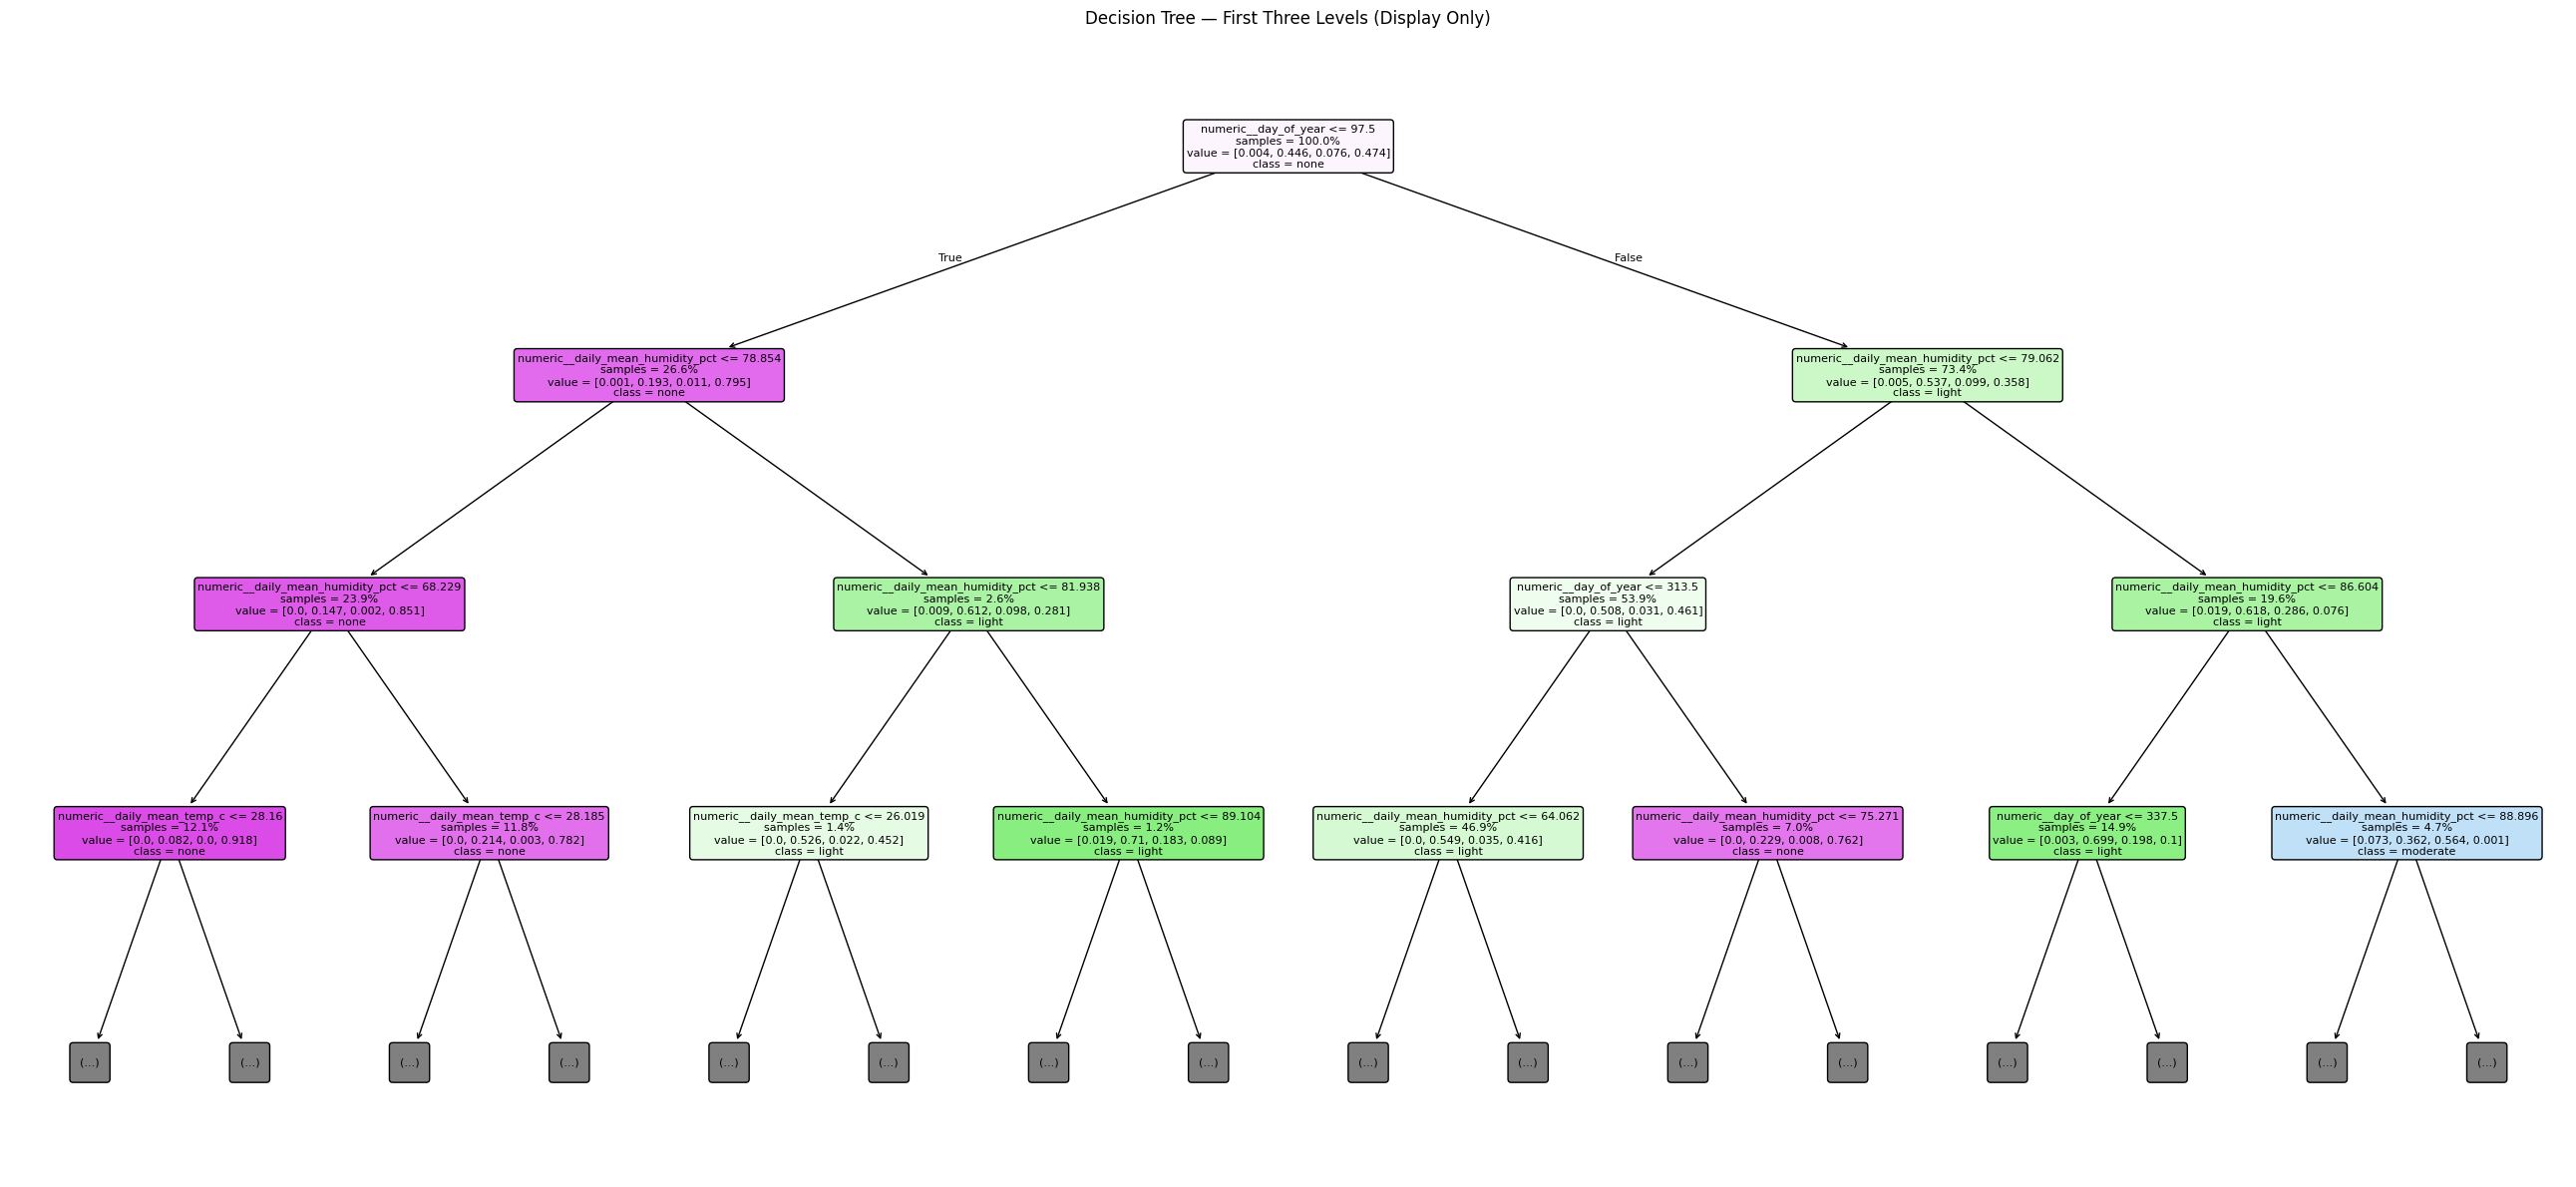

Full trained tree depth: 12
Full trained tree leaves: 1079


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

In [ ]:
# Visualize a readable portion of the trained tree. max_depth limits the plot only,
# not the depth of the fitted decision tree.
fitted_preprocessor = best_tree.named_steps["prep"]
encoded_feature_names = fitted_preprocessor.get_feature_names_out()
tree_model = best_tree.named_steps["tree"]

plt.figure(figsize=(26, 12))
plot_tree(
    tree_model,
    feature_names=encoded_feature_names,
    class_names=[str(c) for c in tree_model.classes_],
    filled=True,
    rounded=True,
    fontsize=8,
    max_depth=3,
    proportion=True,
    impurity=False
)
plt.title("Decision Tree — First Three Levels (Display Only)")
plt.tight_layout()
plt.show()
print("Full trained tree depth:", tree_model.get_depth())
print("Full trained tree leaves:", tree_model.get_n_leaves())


In [ ]:
# Show the decision path for up to five held-out observations.
if len(X_test) == 0:
    print("No held-out test observations are available for tracing.")
else:
    transformed_test = best_tree.named_steps["prep"].transform(X_test.iloc[:5])
    if hasattr(transformed_test, "toarray"):
        transformed_test = transformed_test.toarray()

    decision_paths = tree_model.decision_path(transformed_test)
    leaf_ids = tree_model.apply(transformed_test)
    feature_names = list(encoded_feature_names)

    for row_idx in range(min(5, len(X_test))):
        node_ids = decision_paths.indices[
            decision_paths.indptr[row_idx]:decision_paths.indptr[row_idx + 1]
        ]
        print(f"\nTRACE {row_idx + 1}")
        print("Input:", X_test.iloc[row_idx].to_dict())

        for node_id in node_ids:
            if node_id == leaf_ids[row_idx]:
                class_index = int(np.argmax(tree_model.tree_.value[node_id][0]))
                print(f"  -> LEAF {node_id}: predicted={tree_model.classes_[class_index]}")
                continue

            feat_idx = tree_model.tree_.feature[node_id]
            threshold = tree_model.tree_.threshold[node_id]
            value = transformed_test[row_idx, feat_idx]
            op = "<=" if value <= threshold else ">"
            print(
                f"  Node {node_id}: {feature_names[feat_idx]} = {value:.3f} "
                f"{op} threshold {threshold:.3f}"
            )

        predicted = best_tree.predict(X_test.iloc[[row_idx]])[0]
        print("Actual:", y_test.iloc[row_idx], "Predicted:", predicted)


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag


TRACE 1
Input: {'daily_mean_temp_c': 25.929166666666664, 'daily_mean_humidity_pct': 79.54166666666667, 'month': 1, 'day_of_year': 1, 'district': 'Nagapattinam'}
  Node 0: numeric__day_of_year = 1.000 <= threshold 97.500
  Node 1: numeric__daily_mean_humidity_pct = 79.542 > threshold 78.854
  Node 419: numeric__daily_mean_humidity_pct = 79.542 <= threshold 81.938
  Node 420: numeric__daily_mean_temp_c = 25.929 <= threshold 26.019
  Node 421: numeric__day_of_year = 1.000 <= threshold 21.500
  Node 422: numeric__day_of_year = 1.000 <= threshold 12.500
  Node 423: numeric__day_of_year = 1.000 <= threshold 7.500
  Node 424: numeric__daily_mean_humidity_pct = 79.542 <= threshold 80.354
  Node 425: numeric__day_of_year = 1.000 <= threshold 2.500
  -> LEAF 426: predicted=none
Actual: none Predicted: none

TRACE 2
Input: {'daily_mean_temp_c': 25.329166666666666, 'daily_mean_humidity_pct': 79.04166666666667, 'month': 1, 'day_of_year': 1, 'district': 'Ariyalur'}
  Node 0: numeric__day_of_year = 

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

## Interpretation and reporting notes

- Frequent itemsets and rules describe co-occurrence in daily weather categories; they do not prove causation.
- Support is the fraction of daily district transactions containing an itemset. Confidence is the conditional frequency of the consequent given the antecedent. Lift compares confidence against the consequent's baseline frequency.
- The decision tree predicts a discretized daily rain category, not a continuous rainfall amount. Its score depends on the temporal split and class imbalance; inspect per-class precision/recall, not accuracy alone.
- DIC and Pincer Search here are educational variants intended to expose their core ideas. For a research-grade implementation, document exact algorithm details and validate against a trusted implementation.
- Save your notebook and export the benchmark, rules, and classification report if your project rubric requires standalone result files.

In [ ]:
# Optional: save key outputs to CSV for project documentation
benchmark_df.to_csv("/content/algorithm_benchmark.csv",index=False)
rules_df.to_csv("/content/weather_association_rules.csv",index=False)
grid_results.to_csv("/content/decision_tree_hyperparameter_results.csv",index=False)
print("Saved: /content/algorithm_benchmark.csv")
print("Saved: /content/weather_association_rules.csv")
print("Saved: /content/decision_tree_hyperparameter_results.csv")


Saved: /content/algorithm_benchmark.csv
Saved: /content/weather_association_rules.csv
Saved: /content/decision_tree_hyperparameter_results.csv


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

In [ ]:
import pandas as pd
from sklearn.metrics import classification_report, confusion_matrix

print("ACTUAL TRAINING CLASS DISTRIBUTION")
print(y_train.value_counts())
print("\nTraining proportions:")
print(y_train.value_counts(normalize=True).round(4))

print("\nACTUAL TEST CLASS DISTRIBUTION")
print(y_test.value_counts())
print("\nTest proportions:")
print(y_test.value_counts(normalize=True).round(4))

test_predictions = best_tree.predict(X_test)

print("\nPREDICTED TEST CLASS DISTRIBUTION")
print(pd.Series(test_predictions).value_counts())
print("\nPredicted proportions:")
print(pd.Series(test_predictions).value_counts(normalize=True).round(4))

print("\nCLASSIFICATION REPORT")
print(classification_report(
    y_test,
    test_predictions,
    labels=["none", "light", "moderate", "heavy"],
    zero_division=0
))

print("\nCONFUSION MATRIX")
display(pd.DataFrame(
    confusion_matrix(
        y_test,
        test_predictions,
        labels=["none", "light", "moderate", "heavy"]
    ),
    index=["Actual none", "Actual light", "Actual moderate", "Actual heavy"],
    columns=["Pred none", "Pred light", "Pred moderate", "Pred heavy"]
))

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

ACTUAL TRAINING CLASS DISTRIBUTION
rain_category
none        52666
light       49512
moderate     8404
heavy         454
Name: count, dtype: int64

Training proportions:
rain_category
none        0.4743
light       0.4459
moderate    0.0757
heavy       0.0041
Name: proportion, dtype: float64

ACTUAL TEST CLASS DISTRIBUTION
rain_category
light       13382
none        11666
moderate     2572
heavy         158
Name: count, dtype: int64

Test proportions:
rain_category
light       0.4817
none        0.4200
moderate    0.0926
heavy       0.0057
Name: proportion, dtype: float64


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag


PREDICTED TEST CLASS DISTRIBUTION
light       14854
none        11369
moderate     1529
heavy          26
Name: count, dtype: int64

Predicted proportions:
light       0.5347
none        0.4093
moderate    0.0550
heavy       0.0009
Name: proportion, dtype: float64

CLASSIFICATION REPORT


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

              precision    recall  f1-score   support

        none       0.74      0.72      0.73     11666
       light       0.67      0.74      0.70     13382
    moderate       0.56      0.33      0.42      2572
       heavy       0.08      0.01      0.02       158

    accuracy                           0.69     27778
   macro avg       0.51      0.45      0.47     27778
weighted avg       0.68      0.69      0.68     27778


CONFUSION MATRIX


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,Pred none,Pred light,Pred moderate,Pred heavy
Actual none,8388,3272,6,0
Actual light,2937,9891,547,7
Actual moderate,44,1650,861,17
Actual heavy,0,41,115,2


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag